# Offensive Language Detection in Tamil–English Code-Mixed Social Media Text
### UCS3564 Natural Language Processing — Micro Project (Regulations R2024, Semester V, 2026–27 ODD)
**Theme 1:** Multilingual hate speech / offensive language detection for Tamil and English code-mixed text

| Team member | Register number |
|---|---|
| Arjun Balaji | 3122245001022 |
| Harsha Harirajan | 3122245001056 |

**How to run:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
Full run ≈ 25–35 min on a T4. Set `fast_mode=True` in the config cell for a ≈ 6 min smoke test (lower scores).

| Section | Work Expected item | Rubric criterion |
|---|---|---|
| §1 Problem formulation & literature survey | (i) | Problem statement & formulation (10%) |
| §2 Data preparation | (ii) | Design / Implementation |
| §3 System design + core module | (iii) | Design (25%) |
| §4 Classical baseline | (iv) | Implementation (25%) |
| §5 Transformer component + model card | (v) | Implementation (25%) |
| §6 Evaluation, comparison, error analysis | (vi) | Testing / Implementation |
| §7 Edge cases, constraints, latency & memory | (vii) | Handling of edge cases (10%) |
| §8 Testing (unit + behavioural + golden set) | (vi), (vii) | Testing (10%) |
| §9 Live demo (Gradio app + API) | (viii) | Demo (10%) |
| §10 Deliverables (README, requirements, run script, results) | Deliverables | Teamwork & submission (10%) |

In [ ]:
# ---- Environment setup (Colab already ships torch, transformers, scikit-learn) ----
!pip -q install gradio datasets psutil

In [ ]:
import os, sys, json, time, math, random, re, gc, shutil, platform, contextlib, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

# ---------------- Project layout ----------------
PROJECT_DIR = "/content/nlp_project" if os.path.exists("/content") else os.path.abspath("nlp_project")
ART_DIR  = os.path.join(PROJECT_DIR, "artifacts")    # trained models + inference config
FIG_DIR  = os.path.join(PROJECT_DIR, "figures")      # figures for the IEEE report
DATA_DIR = os.path.join(PROJECT_DIR, "data")         # fixed train/val/test split
for d in (PROJECT_DIR, ART_DIR, FIG_DIR, DATA_DIR):
    os.makedirs(d, exist_ok=True)
os.chdir(PROJECT_DIR)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

# ---------------- Configuration (single source of truth) ----------------
CFG = dict(
    seed=42,
    fast_mode=False,                     # True = quick smoke test on a 4k-example subsample, 1 epoch
    model_name="google/muril-base-cased",
    fallback_model="xlm-roberta-base",   # used automatically if MuRIL cannot be downloaded
    epochs=3,
    batch_size=32,
    lr=2e-5,
    weight_decay=0.01,
    warmup_ratio=0.1,
    max_len_cap=128,                     # actual max_len is chosen from the token-length distribution (§5)
    stride=32,                           # overlap between sliding-window chunks for long inputs (§7)
    grad_clip=1.0,
    patience=1,                          # early stopping on validation macro-F1
    fp16=True,
)
if CFG["fast_mode"]:
    CFG["epochs"] = 1

SEED = CFG["seed"]
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda" and CFG["fp16"]
def amp_ctx():
    return torch.autocast("cuda", dtype=torch.float16) if USE_AMP else contextlib.nullcontext()

RESULTS = {}   # everything measured goes here and is written to results.json at the end
print(f"Python {platform.python_version()} | torch {torch.__version__} | device: {DEVICE}")
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU detected. Training will be very slow. Use Runtime -> Change runtime type -> T4 GPU.")

Python 3.13.15 | torch 2.11.0+cu130 | device: cuda
GPU: Tesla T4


---
## §1 Problem Formulation *(Work Expected i · CO1–CO5)*

### 1.1 Application
An **automated moderation assistant for Tamil social-media comments** (YouTube, Instagram, fan pages, campus groups). Most Tamil users write in **code-mixed text**: romanized Tamil ("Tanglish") mixed with English words, sometimes with Tamil script. English-only or monolingual Tamil tools handle this badly. The system flags offensive comments and says *who* they target, so moderators can prioritise.

### 1.2 Input and output
| | Description |
|---|---|
| **Input** | One raw comment string, in any script and any length. It may also be empty, emoji-only, or in another language. |
| **Output** | One of 6 labels, plus class probabilities, a confidence score, and status flags (`ok`, `uncertain`, `out_of_scope_language`, `empty_input`) with human-readable warnings. |
| **Labels** | `Not_offensive`, `Offensive_Untargeted`, `Offensive_Targeted_Individual`, `Offensive_Targeted_Group`, `Offensive_Targeted_Other`, `Not_Tamil` |

### 1.3 Users and real-world need
* **Primary users:** content moderators and channel admins for Tamil-language pages, and trust-and-safety teams at platforms.
* **Secondary users:** researchers studying online abuse in Dravidian languages.
* **Need:** comment volume is far too high for manual review. Keyword filters miss romanized spellings (e.g. elongations, creative spelling) and produce false alarms on benign slang. A model that understands code-mixed text and **abstains when unsure** lets humans review only the hard cases.

### 1.4 Measurable success criteria (fixed *before* experiments)
| ID | Criterion | Target | Measured in |
|---|---|---|---|
| S1 | Transformer weighted-F1 on held-out test set | ≥ 0.74 | §6 |
| S2 | Transformer macro-F1 improvement over classical baseline | ≥ +0.03 | §6 |
| S3 | Difference vs baseline is statistically significant | McNemar p < 0.05 | §6 |
| S4 | Single-comment latency on GPU (p95) | ≤ 50 ms | §7 |
| S5 | Single-comment latency on CPU (p95) | ≤ 500 ms | §7 |
| S6 | All edge-case categories return an explicit status without crashing | 100 % | §7, §8 |

We report **macro-F1** as the primary metric. Weighted-F1 (the shared-task metric) is dominated by the majority `Not_offensive` class, so it hides failures on rare classes.

### 1.5 Literature survey
| # | Paper | Contribution | Limitation relevant to us |
|---|---|---|---|
| 1 | Chakravarthi et al., *Findings of the Shared Task on Offensive Language Identification in Tamil, Malayalam, and Kannada*, DravidianLangTech @ EACL 2021 | Defined the 6-class code-mixed task and dataset used here. Compared many team systems; multilingual transformers led. | Ranked systems by **weighted-F1**, which rewards majority-class performance. No robustness or deployment evaluation. |
| 2 | Chakravarthi et al., *DravidianCodeMix: sentiment analysis and offensive language identification dataset for Dravidian languages in code-mixed text*, Language Resources and Evaluation, 2022 | Full description of the YouTube-comment corpus, annotation process and baselines. | Mostly classical and early neural baselines. Minority offensive classes stay weak. |
| 3 | Jayanthi & Gupta, *SJ_AJ@DravidianLangTech-EACL2021: Task-Adaptive Pre-Training of Multilingual BERT Models for Offensive Language Identification*, 2021 | Task-adaptive pre-training of mBERT/XLM-R on the task data; one of the strongest shared-task systems. | Needs extra pre-training compute. No analysis of long inputs, abstention or latency. |
| 4 | Hande et al., *Offensive Language Identification in Low-resourced Code-mixed Dravidian Languages using Pseudo-labeling*, arXiv 2021 | Pseudo-labelling and cross-lingual data pooling to fight data scarcity. | Focus on accuracy. Class imbalance and out-of-scope inputs are not handled at inference. |
| 5 | Khanuja et al., *MuRIL: Multilingual Representations for Indian Languages*, arXiv 2021 | BERT model pre-trained on 17 Indian languages **including transliterated (romanized) text**, which is exactly our input style. | General-purpose encoder; needs task fine-tuning. |
| 6 | Kakwani et al., *IndicNLPSuite … and Pre-trained Multilingual Language Models for Indian Languages (IndicBERT)*, Findings of EMNLP 2020 | Compact ALBERT-based Indic model and benchmarks. | Trained on native scripts, so it is weaker on romanized code-mixed text. |
| 7 | Conneau et al., *Unsupervised Cross-lingual Representation Learning at Scale (XLM-R)*, ACL 2020 | Strong multilingual encoder (100 languages); our fallback model. | Little romanized Indic text in pre-training. |

### 1.6 Gap we address
Published systems optimise a leaderboard metric on clean, short inputs. We address three practical gaps:
1. **Minority classes:** we train with a class-weighted loss and report macro-F1 and per-class scores, not just weighted-F1.
2. **Robustness:** we handle empty or emoji-only input, inputs longer than the 512/128-token window (sliding-window aggregation), non-Tamil scripts (script guard), and uncertain predictions (confidence-threshold abstention for unseen categories).
3. **Deployability:** we measure single-inference latency and memory on GPU and CPU, and ship a working web demo and API.

---
## §2 Data Preparation *(Work Expected ii · CO1)*
**Corpus:** *Offenseval Dravidian*, Tamil configuration. These are YouTube comments on Tamil movie trailers, annotated by the DravidianLangTech organisers. We load it from the Hugging Face Hub (`community-datasets/offenseval_dravidian`, licence **CC BY 4.0**).

In [ ]:
LABELS = ["Not_offensive", "Offensive_Untargeted", "Offensive_Targeted_Individual",
          "Offensive_Targeted_Group", "Offensive_Targeted_Other", "Not_Tamil"]
SHORT  = ["NOT", "UNT", "IND", "GRP", "OTH", "NT"]      # short names for plots
OFF_IDS = [1, 2, 3, 4]

from datasets import load_dataset
try:
    ds = load_dataset("community-datasets/offenseval_dravidian", "tamil")
    raw_train = ds["train"].to_pandas()
    raw_test  = ds["validation"].to_pandas()
    src_names = ds["train"].features["label"].names
except Exception as e:
    print("load_dataset failed, falling back to direct parquet download:", repr(e)[:200])
    base = "hf://datasets/community-datasets/offenseval_dravidian/tamil/"
    raw_train = pd.read_parquet(base + "train-00000-of-00001.parquet")
    raw_test  = pd.read_parquet(base + "validation-00000-of-00001.parquet")
    src_names = ["Not_offensive", "Offensive_Untargetede", "Offensive_Targeted_Insult_Individual",
                 "Offensive_Targeted_Insult_Group", "Offensive_Targeted_Insult_Other", "not-Tamil"]

print("Original label names -> our names:")
for i, (s, t) in enumerate(zip(src_names, LABELS)):
    print(f"  {i}: {s:40s} -> {t}")
print(f"\nOfficial train: {len(raw_train):,} rows | official validation: {len(raw_test):,} rows")
display(raw_train.sample(8, random_state=SEED))

README.md:   0%|          | 0.00/15.5k [00:00<?, ?B/s]

tamil/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.39MB            

tamil/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

tamil/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  298kB            

tamil/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/35139 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4388 [00:00<?, ? examples/s]

Original label names -> our names:
  0: Not_offensive                            -> Not_offensive
  1: Offensive_Untargetede                    -> Offensive_Untargeted
  2: Offensive_Targeted_Insult_Individual     -> Offensive_Targeted_Individual
  3: Offensive_Targeted_Insult_Group          -> Offensive_Targeted_Group
  4: Offensive_Targeted_Insult_Other          -> Offensive_Targeted_Other
  5: not-Tamil                                -> Not_Tamil

Official train: 35,139 rows | official validation: 4,388 rows


,text,label
19484,762 k likes reached aairuku pangalingala adich...,0
34941,Yaaruda moonsooru vaayana joke ku edukkirathu ...,2
31609,Naanum thala fan than ennoda channel lai subec...,0
4342,BGM verithanam nu solravanga oru like,0
26624,இப்படிப் படிச்ச பசங்க வேணாம் வேணாம்னு சொல்லி ஓ...,0
428,Dubbing padam mari iruku Dhanush ku munnadi El...,2
27171,Neraiya neraiya neraiya #thala #mass emotional,0
11388,சூப்பர் தல உன்னை வெல்ல எவரும் இல்லை இந்த உலகில்,0


,train (official),validation (official),train %
Not_offensive,25425,3193,72.36
Offensive_Untargeted,2906,356,8.27
Offensive_Targeted_Individual,2343,307,6.67
Offensive_Targeted_Group,2557,295,7.28
Offensive_Targeted_Other,454,65,1.29
Not_Tamil,1454,172,4.14


Words per comment: mean 10.4, median 8, 95th pct 22, max 127


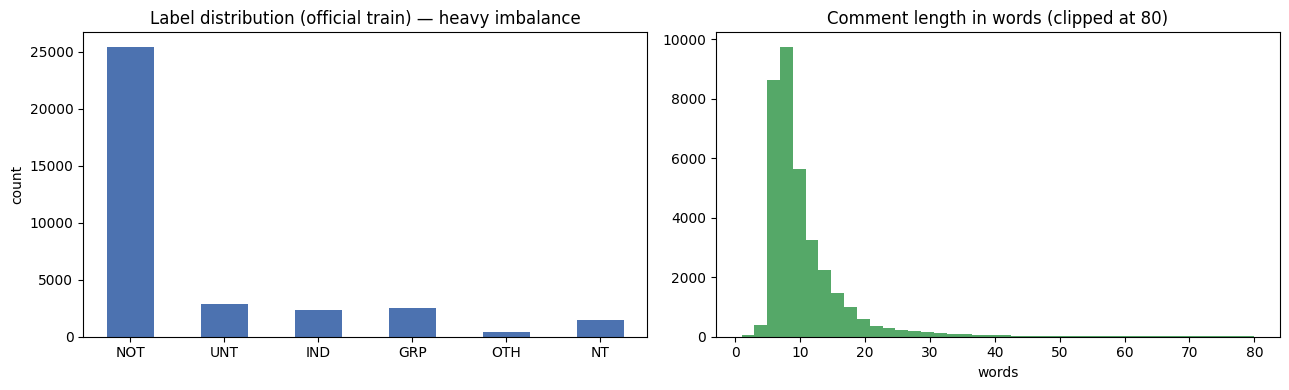

In [ ]:
# ---- Corpus statistics ----
dist = pd.DataFrame({
    "train (official)": raw_train.label.value_counts().sort_index(),
    "validation (official)": raw_test.label.value_counts().sort_index(),
})
dist.index = [LABELS[i] for i in dist.index]
dist["train %"] = (100 * dist["train (official)"] / dist["train (official)"].sum()).round(2)
display(dist)

n_words = raw_train.text.astype(str).str.split().str.len()
print(f"Words per comment: mean {n_words.mean():.1f}, median {n_words.median():.0f}, "
      f"95th pct {n_words.quantile(.95):.0f}, max {n_words.max()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dist["train (official)"].plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Label distribution (official train) — heavy imbalance")
axes[0].set_xticklabels(SHORT, rotation=0); axes[0].set_ylabel("count")
axes[1].hist(n_words.clip(upper=80), bins=40, color="#55A868")
axes[1].set_title("Comment length in words (clipped at 80)"); axes[1].set_xlabel("words")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/data_overview.png", dpi=150); plt.show()

In [ ]:
# ---- Cleaning: empties, conflicting duplicates, exact duplicates, train/test leakage ----
def to_str(df):
    df = df.copy(); df["text"] = df["text"].astype(str); return df

train_all, test_df = to_str(raw_train), to_str(raw_test)
log = [("official train", len(train_all))]

train_all = train_all[train_all.text.str.strip().str.len() > 0]
log.append(("after removing empty texts", len(train_all)))

n_labels_per_text = train_all.groupby("text").label.nunique()
conflicting = set(n_labels_per_text[n_labels_per_text > 1].index)
train_all = train_all[~train_all.text.isin(conflicting)]
log.append((f"after removing {len(conflicting)} texts with conflicting labels", len(train_all)))

train_all = train_all.drop_duplicates("text")
log.append(("after removing exact duplicates", len(train_all)))

leak = train_all.text.isin(set(test_df.text))
train_all = train_all[~leak]
log.append((f"after removing {int(leak.sum())} texts that also occur in the test set", len(train_all)))

test_df = test_df[test_df.text.str.strip().str.len() > 0].reset_index(drop=True)
display(pd.DataFrame(log, columns=["step", "rows"]))
RESULTS["data_cleaning"] = dict(log)

,step,rows
0,official train,35139
1,after removing empty texts,35139
2,after removing 13 texts with conflicting labels,35106
3,after removing exact duplicates,34870
4,after removing 54 texts that also occur in the...,34816


In [ ]:
# ---- Fixed split: official validation = held-out TEST; official train -> 90% train / 10% validation ----
from sklearn.model_selection import train_test_split
train_df, val_df = train_test_split(train_all, test_size=0.10, stratify=train_all.label, random_state=SEED)
if CFG["fast_mode"]:
    train_df, _ = train_test_split(train_df, train_size=4000, stratify=train_df.label, random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d[["text", "label"]].to_csv(f"{DATA_DIR}/{name}.csv", index=False)

y_tr, y_va, y_te = train_df.label.values, val_df.label.values, test_df.label.values
split_tbl = pd.DataFrame({n: pd.Series(y).value_counts().sort_index() for n, y in
                          [("train", y_tr), ("val", y_va), ("test", y_te)]})
split_tbl.index = LABELS
split_tbl.loc["TOTAL"] = split_tbl.sum()
display(split_tbl)

display(Markdown(f"""
### 2.1 Dataset documentation
| Item | Value |
|---|---|
| Name | Offenseval Dravidian (Tamil), DravidianLangTech @ EACL 2021 |
| Source | YouTube comments on Tamil movie trailers |
| Hub id | `community-datasets/offenseval_dravidian`, config `tamil` |
| Licence | **CC BY 4.0**, attribution to Chakravarthi et al. (2021, 2022) |
| Size (official) | {len(raw_train):,} train + {len(raw_test):,} validation comments |
| Size (after cleaning) | {len(train_df):,} train / {len(val_df):,} val / {len(test_df):,} test |
| Split policy | Official validation used as **held-out test**. Official train split 90/10 **stratified**, `random_state={SEED}`. Split saved to `data/*.csv`. |
| Language/script | Mostly romanized Tamil with English (code-mixed); some Tamil script; some other languages (`Not_Tamil`) |
"""))

,train,val,test
Not_offensive,22644,2516,3193
Offensive_Untargeted,2596,289,356
Offensive_Targeted_Individual,2100,233,307
Offensive_Targeted_Group,2288,254,295
Offensive_Targeted_Other,407,45,65
Not_Tamil,1299,145,172
TOTAL,31334,3482,4388



### 2.1 Dataset documentation
| Item | Value |
|---|---|
| Name | Offenseval Dravidian (Tamil), DravidianLangTech @ EACL 2021 |
| Source | YouTube comments on Tamil movie trailers |
| Hub id | `community-datasets/offenseval_dravidian`, config `tamil` |
| Licence | **CC BY 4.0**, attribution to Chakravarthi et al. (2021, 2022) |
| Size (official) | 35,139 train + 4,388 validation comments |
| Size (after cleaning) | 31,334 train / 3,482 val / 4,388 test |
| Split policy | Official validation used as **held-out test**. Official train split 90/10 **stratified**, `random_state=42`. Split saved to `data/*.csv`. |
| Language/script | Mostly romanized Tamil with English (code-mixed); some Tamil script; some other languages (`Not_Tamil`) |


### 2.2 Annotation scheme
We use the **original expert annotation** and do not re-label anything. Each comment has exactly one label:

| Label | Meaning |
|---|---|
| `Not_offensive` | No offence or profanity |
| `Offensive_Untargeted` | Profanity or offence with no clear target |
| `Offensive_Targeted_Individual` | Insult aimed at a specific person |
| `Offensive_Targeted_Group` | Insult aimed at a group (community, fans of an actor, a gender, …) |
| `Offensive_Targeted_Other` | Insult aimed at something else (an organisation, event, issue) |
| `Not_Tamil` | Comment not written in Tamil (in either script) |

The cleaning step above removed comments that appear with **conflicting labels**. This is a sign of annotation noise, and we come back to it in the error analysis.

---
## §3 System Design *(Work Expected iii · CO1–CO5)*

The system is a modular pipeline. Every module lives in **`nlp_core.py`** (written below), so the notebook, the tests, the Gradio demo and the standalone `app.py` all share the *same* code path.

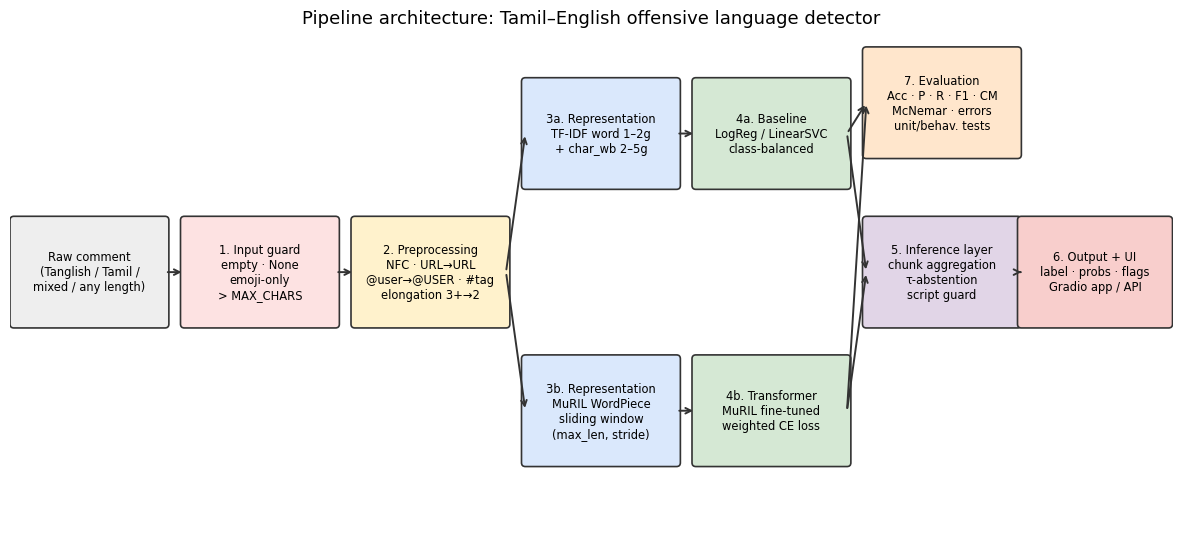

In [ ]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(15, 6.5)); ax.set_xlim(0, 15); ax.set_ylim(-0.2, 6.3); ax.axis("off")
def box(x, y, txt, fc, w=1.95, h=1.35):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=fc, ec="#333", lw=1.2))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=8.3)
    return (x, y, w, h)
def arrow(a, b):
    ax.annotate("", xy=(b[0], b[1] + b[3] / 2), xytext=(a[0] + a[2], a[1] + a[3] / 2),
                arrowprops=dict(arrowstyle="->", lw=1.4, color="#333"))
inp  = box(0.05, 2.5, "Raw comment\n(Tanglish / Tamil /\nmixed / any length)", "#eeeeee")
grd  = box(2.25, 2.5, "1. Input guard\nempty · None\nemoji-only\n> MAX_CHARS", "#fde2e2")
prep = box(4.45, 2.5, "2. Preprocessing\nNFC · URL→URL\n@user→@USER · #tag\nelongation 3+→2", "#fff2cc")
repA = box(6.65, 4.3, "3a. Representation\nTF-IDF word 1–2g\n+ char_wb 2–5g", "#dae8fc")
repB = box(6.65, 0.7, "3b. Representation\nMuRIL WordPiece\nsliding window\n(max_len, stride)", "#dae8fc")
modA = box(8.85, 4.3, "4a. Baseline\nLogReg / LinearSVC\nclass-balanced", "#d5e8d4")
modB = box(8.85, 0.7, "4b. Transformer\nMuRIL fine-tuned\nweighted CE loss", "#d5e8d4")
infr = box(11.05, 2.5, "5. Inference layer\nchunk aggregation\nτ-abstention\nscript guard", "#e1d5e7")
outp = box(13.05, 2.5, "6. Output + UI\nlabel · probs · flags\nGradio app / API", "#f8cecc", w=1.9)
evl  = box(11.05, 4.7, "7. Evaluation\nAcc · P · R · F1 · CM\nMcNemar · errors\nunit/behav. tests", "#ffe6cc")
for a, b in [(inp, grd), (grd, prep), (prep, repA), (prep, repB), (repA, modA), (repB, modB),
             (modA, infr), (modB, infr), (infr, outp), (modA, evl), (modB, evl)]:
    arrow(a, b)
ax.set_title("Pipeline architecture: Tamil–English offensive language detector", fontsize=13)
plt.savefig(f"{FIG_DIR}/architecture.png", dpi=170, bbox_inches="tight"); plt.show()

### 3.1 Module breakdown and technology justification
| Module | Choice | Why this choice (alternatives considered) |
|---|---|---|
| Input guard | Rule-based checks | Deterministic, zero cost. Stops crashes and wasted compute on empty, huge or emoji-only input. |
| Preprocessing | Unicode NFC, URL/mention/hashtag normalisation, elongation squashing (`semmaaaa`→`semmaa`) | Tanglish has heavy creative spelling. Normalising cuts the vocabulary without losing meaning. We **keep emojis and casing** for the transformer because they carry sentiment. No stop-word removal, because negations and pronouns matter for offence. |
| Script identification | Unicode-block ratios (Tamil / Latin / other) | Cheap way to flag out-of-scope languages. Also drives the error analysis by script. |
| Representation A | TF-IDF, word 1–2-grams + **character** 2–5-grams | Character n-grams are robust to romanized spelling variation. Strong classical baseline for noisy text. |
| Model A | Logistic Regression / Linear SVM, `class_weight="balanced"` | Fast, interpretable, well-calibrated (LR). Picked by validation macro-F1. |
| Representation B | MuRIL WordPiece tokens, max_len picked from the data's 99th percentile, sliding window for longer text | Subword tokens handle out-of-vocabulary words. The sliding window removes the fixed-window limit. |
| Model B | **MuRIL** (`google/muril-base-cased`) fine-tuned | Pre-trained on 17 Indian languages **and their transliterations**, which matches romanized Tamil. mBERT and IndicBERT lack transliterated pre-training. XLM-R is the automatic fallback. |
| Loss | Cross-entropy with √(balanced) class weights | Full inverse-frequency weights (up to ~13×) destabilise fine-tuning. The square root is a compromise that boosts rare classes. |
| Inference | Max-offensive-chunk aggregation, confidence threshold τ, script guard | One offensive sentence makes a long comment offensive, so we use max rather than mean. τ gives abstention for unseen categories. |
| Interface | Gradio (web UI + auto-generated REST API) | Runs inside Colab with a public link. The same function serves the UI and the API. |

In [ ]:
%%writefile nlp_core.py
"""nlp_core.py - shared modules for the Tamil-English offensive language detector.

Modules: preprocessing, script identification, input guard, transformer predictor
(sliding window + abstention) and classical baseline predictor. Used by the notebook,
the tests and the Gradio app so that every entry point runs the same code path.
"""
import json
import os
import re
import time
import unicodedata

import numpy as np

LABELS = ["Not_offensive", "Offensive_Untargeted", "Offensive_Targeted_Individual",
          "Offensive_Targeted_Group", "Offensive_Targeted_Other", "Not_Tamil"]
PRETTY = {
    "Not_offensive": "Not offensive",
    "Offensive_Untargeted": "Offensive (untargeted)",
    "Offensive_Targeted_Individual": "Offensive - targets an individual",
    "Offensive_Targeted_Group": "Offensive - targets a group",
    "Offensive_Targeted_Other": "Offensive - targets something else",
    "Not_Tamil": "Not Tamil (out of scope)",
}
OFFENSIVE_IDS = [1, 2, 3, 4]
MAX_CHARS = 20000          # hard cap to protect latency / memory

# ------------------------------------------------------------------ preprocessing
_URL = re.compile(r"(https?://\S+|www\.\S+)", re.I)
_MENTION = re.compile(r"@\w+")
_HASHTAG = re.compile(r"#(\w+)")
_ELONG = re.compile(r"([^\d\s])\1{2,}")   # keeps numbers like 1000 intact
_WS = re.compile(r"\s+")


def clean_text(text, lower=False):
    """Normalise a raw comment. Safe on None / non-string input."""
    if text is None:
        return ""
    text = unicodedata.normalize("NFC", str(text))
    text = _URL.sub(" URL ", text)
    text = _MENTION.sub(" @USER ", text)
    text = _HASHTAG.sub(r" \1 ", text)
    text = _ELONG.sub(r"\1\1", text)          # sooooo -> soo, !!!!! -> !!
    text = _WS.sub(" ", text).strip()
    return text.lower() if lower else text


def clean_lower(text):
    """Module-level (picklable) preprocessor for the TF-IDF baseline."""
    return clean_text(text, lower=True)


def _is_tamil(ch):
    return "\u0B80" <= ch <= "\u0BFF"


def script_profile(text):
    """Fraction of Tamil-script, Latin and other-script letters, plus a coarse type."""
    text = "" if text is None else str(text)
    ta = sum(_is_tamil(c) for c in text)
    la = sum(c.isascii() and c.isalpha() for c in text)
    ot = sum(c.isalpha() and not c.isascii() and not _is_tamil(c) for c in text)
    tot = ta + la + ot
    if tot == 0:
        return {"tamil": 0.0, "latin": 0.0, "other": 0.0, "type": "no letters"}
    r = {"tamil": ta / tot, "latin": la / tot, "other": ot / tot}
    if r["other"] >= 0.5:
        kind = "other script"
    elif r["tamil"] >= 0.8:
        kind = "Tamil script"
    elif r["latin"] >= 0.8:
        kind = "romanized"
    else:
        kind = "mixed script"
    r = {k: round(v, 3) for k, v in r.items()}
    r["type"] = kind
    return r


# ------------------------------------------------------------------ shared inference helpers
def softmax(z):
    z = np.asarray(z, dtype=np.float64)
    z = z - z.max(-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(-1, keepdims=True)


def _base_result(text):
    return {"input_chars": 0 if text is None else len(str(text)), "status": "ok", "label": None,
            "pretty_label": None, "confidence": None, "probs": {}, "warnings": [], "n_chunks": 0,
            "aggregation": None, "script": None, "cleaned": "", "n_tokens": None,
            "unk_ratio": None, "tokens_per_word": None, "latency_ms": None}


def _guard(text, r):
    """Input guard. Returns cleaned text, or None when there is nothing to classify."""
    if text is None or not str(text).strip():
        r["status"] = "empty_input"
        r["warnings"].append("Input is empty - nothing to classify.")
        return None
    text = str(text)
    if len(text) > MAX_CHARS:
        r["warnings"].append(f"Input truncated from {len(text):,} to {MAX_CHARS:,} characters.")
        text = text[:MAX_CHARS]
    cleaned = clean_text(text)
    r["cleaned"] = cleaned
    r["script"] = script_profile(cleaned)
    if not any(c.isalnum() for c in cleaned):
        r["warnings"].append("No letters or digits (emoji/punctuation only) - low-evidence prediction.")
    return cleaned


def _finalise(probs, r, tau, t0):
    pid = int(np.argmax(probs))
    conf = float(probs[pid])
    r["label"] = LABELS[pid]
    r["pretty_label"] = PRETTY[LABELS[pid]]
    r["confidence"] = round(conf, 4)
    r["probs"] = {LABELS[i]: float(p) for i, p in enumerate(probs)}
    if r["script"] and r["script"]["type"] == "other script":
        r["status"] = "out_of_scope_language"
        r["warnings"].append("Mostly non-Tamil, non-Latin script - outside the training distribution.")
    elif conf < tau:
        r["status"] = "uncertain"
        r["warnings"].append(f"Confidence {conf:.2f} < threshold tau={tau:.2f}: abstain and route to a human.")
    r["latency_ms"] = round((time.perf_counter() - t0) * 1000, 2)
    return r


def save_config(art_dir, cfg):
    with open(os.path.join(art_dir, "inference_config.json"), "w") as f:
        json.dump(cfg, f, indent=2)


def load_config(art_dir):
    with open(os.path.join(art_dir, "inference_config.json")) as f:
        return json.load(f)


# ------------------------------------------------------------------ transformer predictor
class TransformerPredictor:
    """Fine-tuned encoder + sliding window for long input + confidence abstention."""

    def __init__(self, model_dir=None, device=None, max_len=128, stride=32, tau=0.0,
                 model=None, tokenizer=None):
        import torch
        from transformers import AutoModelForSequenceClassification, AutoTokenizer
        from transformers.utils import logging as hf_logging
        hf_logging.set_verbosity_error()
        self.torch = torch
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.tok = tokenizer if tokenizer is not None else AutoTokenizer.from_pretrained(model_dir)
        m = model if model is not None else AutoModelForSequenceClassification.from_pretrained(model_dir)
        self.model = m.to(self.device).eval()
        self.max_len, self.stride, self.tau = int(max_len), int(stride), float(tau)
        self.name = "MuRIL transformer"

    @classmethod
    def from_artifacts(cls, art_dir, device=None):
        cfg = load_config(art_dir)
        return cls(os.path.join(art_dir, "transformer"), device=device, max_len=cfg["max_len"],
                   stride=cfg["stride"], tau=cfg["tau"])

    def chunk_probs(self, cleaned):
        enc = self.tok(cleaned, truncation=True, max_length=self.max_len, stride=self.stride,
                       return_overflowing_tokens=True, padding=True, return_tensors="pt")
        enc = {k: v.to(self.device) for k, v in enc.items()
               if k in ("input_ids", "attention_mask", "token_type_ids")}
        with self.torch.inference_mode():
            logits = self.model(**enc).logits.float().cpu().numpy()
        return softmax(logits)

    def predict(self, text):
        t0 = time.perf_counter()
        r = _base_result(text)
        cleaned = _guard(text, r)
        if cleaned is None:
            r["latency_ms"] = round((time.perf_counter() - t0) * 1000, 2)
            return r
        ids = self.tok(cleaned, add_special_tokens=False)["input_ids"]
        unk = self.tok.unk_token_id
        r["n_tokens"] = len(ids)
        r["unk_ratio"] = round(sum(i == unk for i in ids) / max(len(ids), 1), 3)
        r["tokens_per_word"] = round(len(ids) / max(len(cleaned.split()), 1), 2)
        if r["unk_ratio"] > 0.2:
            r["warnings"].append(f"{r['unk_ratio']:.0%} of tokens are unknown to the vocabulary.")
        P = self.chunk_probs(cleaned)
        r["n_chunks"] = len(P)
        off = P[:, OFFENSIVE_IDS].sum(1)
        if len(P) > 1 and off.max() > 0.5:
            probs, r["aggregation"] = P[int(off.argmax())], "max-offensive chunk"
        else:
            probs = P.mean(0)
            r["aggregation"] = "mean over chunks" if len(P) > 1 else "single window"
        if len(P) > 1:
            r["warnings"].append(f"Longer than the {self.max_len}-token window: split into {len(P)} "
                                 f"overlapping chunks ({r['aggregation']}).")
        return _finalise(probs, r, self.tau, t0)


# ------------------------------------------------------------------ classical baseline predictor
class BaselinePredictor:
    """TF-IDF + linear classifier behind the same interface as the transformer."""

    def __init__(self, pipeline, tau=0.0):
        self.pipe, self.tau = pipeline, float(tau)
        self.name = "TF-IDF baseline"

    @classmethod
    def from_artifacts(cls, art_dir):
        import joblib
        cfg = load_config(art_dir)
        return cls(joblib.load(os.path.join(art_dir, "baseline.joblib")), tau=cfg.get("baseline_tau", 0.0))

    def predict_proba(self, texts):
        if hasattr(self.pipe, "predict_proba"):
            return self.pipe.predict_proba(texts)
        return softmax(self.pipe.decision_function(texts))

    def predict(self, text):
        t0 = time.perf_counter()
        r = _base_result(text)
        cleaned = _guard(text, r)
        if cleaned is None:
            r["latency_ms"] = round((time.perf_counter() - t0) * 1000, 2)
            return r
        probs = self.predict_proba([cleaned])[0]
        r["n_chunks"], r["aggregation"] = 1, "bag of n-grams (no length limit)"
        return _finalise(probs, r, self.tau, t0)

Writing nlp_core.py


In [ ]:
import importlib, nlp_core
importlib.reload(nlp_core)
from nlp_core import (clean_text, clean_lower, script_profile, softmax, TransformerPredictor,
                      BaselinePredictor, save_config, load_config, PRETTY, MAX_CHARS)
assert nlp_core.LABELS == LABELS

# Preprocessing sanity check on real corpus examples
demo = pd.DataFrame({"raw": train_df.text.sample(6, random_state=1).tolist() +
                     ["Semmaaaaa padam!!!!! @rahul123 check https://youtu.be/xyz #Thalaivar"]})
demo["clean_text"] = demo.raw.map(clean_text)
demo["script"] = demo.raw.map(lambda t: script_profile(t)["type"])
with pd.option_context("display.max_colwidth", 90):
    display(demo)

# Script profile of the corpus (used later in error analysis)
script_dist = pd.crosstab(train_df.text.map(lambda t: script_profile(t)["type"]),
                          train_df.label.map(dict(enumerate(SHORT))), margins=True)
display(Markdown("**Script type × label (train)**")); display(script_dist)

,raw,clean_text,script
0,othinkirunka Da amais ilana adichu underwearoda oda vitruvom.... petta parak....,othinkirunka Da amais ilana adichu underwearoda oda vitruvom.. petta parak..,romanized
1,1:57 semaa thala nalle dha edhala sollamudium thagidi avaruku mattudha eruku,1:57 semaa thala nalle dha edhala sollamudium thagidi avaruku mattudha eruku,romanized
2,All kiccha fans kade enda supprr agide,All kiccha fans kade enda supprr agide,romanized
3,Kaithi Eh Ippadi Na Appea Thalapati 64 ?? Dei Naan Thala Fan da Eanake Veari Asguthu !!,Kaithi Eh Ippadi Na Appea Thalapati 64 ?? Dei Naan Thala Fan da Eanake Veari Asguthu !!,romanized
4,Singham singla thaan varuve Singham Boys like Surya anna,Singham singla thaan varuve Singham Boys like Surya anna,romanized
5,சாதி வெறியைத் தூண்டுகிற படம்..கீழ உள்ள கமெண்ட்ஸ் பாருங்க...புரிந்து கொள்ளலாம்.,சாதி வெறியைத் தூண்டுகிற படம்..கீழ உள்ள கமெண்ட்ஸ் பாருங்க..புரிந்து கொள்ளலாம்.,Tamil script
6,Semmaaaaa padam!!!!! @rahul123 check https://youtu.be/xyz #Thalaivar,Semmaa padam!! @USER check URL Thalaivar,romanized


**Script type × label (train)**

label,GRP,IND,NOT,NT,OTH,UNT,All
text,,,,,,,
Tamil script,662,264,4271,0,62,88,5347
mixed script,46,29,472,31,7,24,609
other script,0,0,9,62,0,0,71
romanized,1580,1807,17892,1206,338,2484,25307
All,2288,2100,22644,1299,407,2596,31334


---
## §4 Classical Baseline *(Work Expected iv · CO1, CO3)*
TF-IDF on word 1–2-grams **and** character 2–5-grams (robust to romanized spelling), then a class-balanced linear classifier. We pick the classifier and `C` on **validation macro-F1** only; the test set is not touched here.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
import joblib

features = FeatureUnion([
    ("word", TfidfVectorizer(preprocessor=clean_lower, analyzer="word", ngram_range=(1, 2), min_df=2,
                             max_features=100_000, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")),
    ("char", TfidfVectorizer(preprocessor=clean_lower, analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                             max_features=200_000, sublinear_tf=True)),
])
t0 = time.time()
Xtr = features.fit_transform(train_df.text.tolist())
Xva = features.transform(val_df.text.tolist())
print(f"TF-IDF matrix: {Xtr.shape[0]:,} x {Xtr.shape[1]:,} features ({time.time()-t0:.1f}s)")

grid = [("LogReg", LogisticRegression, {"C": c, "max_iter": 2000}) for c in (2, 8)] + \
       [("LinearSVC", LinearSVC, {"C": c, "max_iter": 5000}) for c in (0.1, 0.5)]
rows, best = [], None
for name, cls, params in grid:
    t0 = time.time()
    clf = cls(class_weight="balanced", **params).fit(Xtr, y_tr)
    p = clf.predict(Xva)
    row = dict(model=name, C=params["C"], val_macro_f1=f1_score(y_va, p, average="macro"),
               val_weighted_f1=f1_score(y_va, p, average="weighted"),
               val_acc=accuracy_score(y_va, p), fit_s=round(time.time() - t0, 1))
    rows.append(row)
    if best is None or row["val_macro_f1"] > best[0]:
        best = (row["val_macro_f1"], name, params["C"], clf)
display(pd.DataFrame(rows).round(4))
print(f"Selected baseline: {best[1]} (C={best[2]}) - validation macro-F1 {best[0]:.4f}")

baseline_pipe = Pipeline([("features", features), ("clf", best[3])])
joblib.dump(baseline_pipe, f"{ART_DIR}/baseline.joblib")
baseline = BaselinePredictor(baseline_pipe)
BASELINE_NAME = f"TF-IDF (word+char) + {best[1]} (C={best[2]})"
RESULTS["baseline_selection"] = rows

TF-IDF matrix: 31,334 x 159,385 features (9.0s)


,model,C,val_macro_f1,val_weighted_f1,val_acc,fit_s
0,LogReg,2.0,0.4818,0.7398,0.7203,60.6
1,LogReg,8.0,0.4815,0.7522,0.7447,72.8
2,LinearSVC,0.1,0.5009,0.7645,0.7625,2.8
3,LinearSVC,0.5,0.4991,0.7632,0.7645,4.4


Selected baseline: LinearSVC (C=0.1) - validation macro-F1 0.5009


---
## §5 Transformer Component *(Work Expected v · CO5)*
We fine-tune **MuRIL** with a class-weighted cross-entropy loss, mixed precision, a linear warm-up/decay schedule and early stopping on validation macro-F1.

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup, DataCollatorWithPadding)
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

def load_backbone(name):
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)),
        label2id={l: i for i, l in enumerate(LABELS)})
    return tok, model

try:
    tok, model = load_backbone(CFG["model_name"]); MODEL_USED = CFG["model_name"]
except Exception as e:
    print(f"Could not load {CFG['model_name']} ({repr(e)[:150]}); falling back to {CFG['fallback_model']}")
    tok, model = load_backbone(CFG["fallback_model"]); MODEL_USED = CFG["fallback_model"]
print("Backbone:", MODEL_USED, "| parameters:", f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M")

# Cleaned text for all splits (same preprocessing as the deployed predictor)
tr_clean = [clean_text(t) for t in train_df.text]
va_clean = [clean_text(t) for t in val_df.text]
te_clean = [clean_text(t) for t in test_df.text]

# Choose max_len from the data instead of guessing
lens = np.array([len(x) for x in tok(tr_clean, add_special_tokens=True)["input_ids"]])
p50, p95, p99 = np.percentile(lens, [50, 95, 99])
MAX_LEN = int(min(CFG["max_len_cap"], max(64, 16 * math.ceil(p99 / 16))))
print(f"Token lengths: median {p50:.0f}, p95 {p95:.0f}, p99 {p99:.0f}, max {lens.max()} -> MAX_LEN = {MAX_LEN}")
print(f"Train comments longer than MAX_LEN: {(lens > MAX_LEN).mean():.2%} (handled by sliding window at inference)")

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Backbone: google/muril-base-cased | parameters: 237.6M


model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

Token lengths: median 18, p95 48, p99 91, max 261 -> MAX_LEN = 96
Train comments longer than MAX_LEN: 0.83% (handled by sliding window at inference)


In [ ]:
from torch.utils.data import Dataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

class EncodedDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tok(texts, truncation=True, max_length=MAX_LEN)
        self.labels = [int(l) for l in labels]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.enc.keys()}
        item["labels"] = self.labels[i]
        return item

collator = DataCollatorWithPadding(tok)
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(EncodedDataset(tr_clean, y_tr), batch_size=CFG["batch_size"], shuffle=True,
                          collate_fn=collator, generator=g)

@torch.no_grad()
def predict_probs(mdl, texts, bs=128):
    """Batched inference with truncation (used for evaluation; the predictor adds sliding windows)."""
    mdl.eval(); out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(DEVICE)
        with amp_ctx():
            logits = mdl(**enc).logits
        out.append(torch.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(out)

# Class weights: sqrt of 'balanced' inverse-frequency weights, normalised to mean 1
cw = np.sqrt(compute_class_weight("balanced", classes=np.arange(len(LABELS)), y=y_tr))
cw = cw / cw.mean()
display(pd.DataFrame({"label": LABELS, "train count": np.bincount(y_tr, minlength=6), "loss weight": cw.round(3)}))
loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32, device=DEVICE))

,label,train count,loss weight
0,Not_offensive,22644,0.273
1,Offensive_Untargeted,2596,0.805
2,Offensive_Targeted_Individual,2100,0.895
3,Offensive_Targeted_Group,2288,0.857
4,Offensive_Targeted_Other,407,2.033
5,Not_Tamil,1299,1.138


In [ ]:
# ---------------- Fine-tuning loop ----------------
TF_DIR = os.path.join(ART_DIR, "transformer")
set_seed(SEED)
model.to(DEVICE)
no_decay = ("bias", "LayerNorm.weight")
opt = torch.optim.AdamW([
    {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": CFG["weight_decay"]},
    {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0},
], lr=CFG["lr"])
total_steps = len(train_loader) * CFG["epochs"]
sched = get_linear_schedule_with_warmup(opt, int(CFG["warmup_ratio"] * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

history, best_f1, bad_epochs = [], -1.0, 0
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
t_start = time.time()
for epoch in range(1, CFG["epochs"] + 1):
    model.train(); run_loss, seen = 0.0, 0
    pbar = tqdm(train_loader, desc=f"epoch {epoch}/{CFG['epochs']}")
    for step, batch in enumerate(pbar):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        labels = batch.pop("labels")
        with amp_ctx():
            logits = model(**batch).logits
        loss = loss_fn(logits.float(), labels)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(opt); scaler.update(); sched.step()
        run_loss += loss.item() * len(labels); seen += len(labels)
        if step % 50 == 0:
            pbar.set_postfix(loss=f"{run_loss / seen:.4f}")
    va_probs = predict_probs(model, va_clean)
    va_pred = va_probs.argmax(1)
    rec = dict(epoch=epoch, train_loss=run_loss / seen,
               val_loss=float(-np.log(va_probs[np.arange(len(y_va)), y_va] + 1e-12).mean()),
               val_acc=accuracy_score(y_va, va_pred),
               val_macro_f1=f1_score(y_va, va_pred, average="macro"),
               val_weighted_f1=f1_score(y_va, va_pred, average="weighted"))
    history.append(rec); print({k: round(v, 4) for k, v in rec.items()})
    if rec["val_macro_f1"] > best_f1:
        best_f1, bad_epochs = rec["val_macro_f1"], 0
        model.save_pretrained(TF_DIR); tok.save_pretrained(TF_DIR)
        print(f"  -> new best (val macro-F1 {best_f1:.4f}), saved to {TF_DIR}")
    else:
        bad_epochs += 1
        if bad_epochs >= CFG["patience"]:
            print("  -> early stopping"); break

TRAIN_TIME_MIN = (time.time() - t_start) / 60
PEAK_TRAIN_MEM_GB = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else float("nan")
print(f"Training time {TRAIN_TIME_MIN:.1f} min | peak GPU memory {PEAK_TRAIN_MEM_GB:.2f} GB")

# Reload the best checkpoint and free optimizer memory
del opt, scaler, sched; gc.collect()
model = AutoModelForSequenceClassification.from_pretrained(TF_DIR).to(DEVICE).eval()
if DEVICE == "cuda":
    torch.cuda.empty_cache()
RESULTS["training_history"] = history

epoch 1/3:   0%|          | 0/980 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.4958, 'val_loss': 0.9766, 'val_acc': 0.7286, 'val_macro_f1': 0.3231, 'val_weighted_f1': 0.6893}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best (val macro-F1 0.3231), saved to /content/nlp_project/artifacts/transformer


epoch 2/3:   0%|          | 0/980 [00:00<?, ?it/s]

...

epoch 3/3:   0%|          | 0/980 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.0556, 'val_loss': 0.7689, 'val_acc': 0.7453, 'val_macro_f1': 0.3954, 'val_weighted_f1': 0.7257}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best (val macro-F1 0.3954), saved to /content/nlp_project/artifacts/transformer
Training time 10.7 min | peak GPU memory 5.31 GB


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

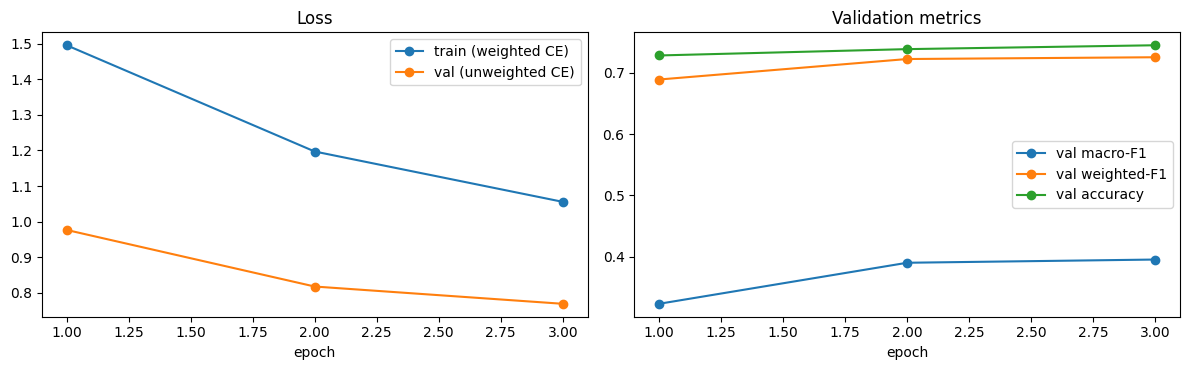

In [ ]:
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(h.epoch, h.train_loss, "o-", label="train (weighted CE)")
axes[0].plot(h.epoch, h.val_loss, "o-", label="val (unweighted CE)")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h.epoch, h.val_macro_f1, "o-", label="val macro-F1")
axes[1].plot(h.epoch, h.val_weighted_f1, "o-", label="val weighted-F1")
axes[1].plot(h.epoch, h.val_acc, "o-", label="val accuracy")
axes[1].set_title("Validation metrics"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/training_curves.png", dpi=150); plt.show()

In [ ]:
# ---------------- Model card (hyper-parameters + compute used) ----------------
gpu_name = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only"
import transformers as _tf
MODEL_CARD = f"""# Model card - Tamil-English offensive language classifier

| Field | Value |
|---|---|
| Base model | `{MODEL_USED}` (BERT-base architecture, {sum(p.numel() for p in model.parameters())/1e6:.1f}M parameters) |
| Task | 6-class offensive language identification (code-mixed Tamil-English) |
| Training data | Offenseval Dravidian (Tamil), {len(train_df):,} train / {len(val_df):,} val, CC BY 4.0 |
| Preprocessing | NFC, URL/@mention/#hashtag normalisation, elongation squashing; casing and emojis kept |
| Max sequence length | {MAX_LEN} tokens (p99 of training data, capped); sliding window (stride {CFG['stride']}) at inference |
| Epochs (max / run) | {CFG['epochs']} / {len(history)} (early stopping on val macro-F1, patience {CFG['patience']}) |
| Batch size | {CFG['batch_size']} |
| Optimiser | AdamW, lr {CFG['lr']}, weight decay {CFG['weight_decay']}, linear schedule, warm-up {CFG['warmup_ratio']:.0%} |
| Loss | Cross-entropy, class weights = sqrt(balanced), normalised |
| Gradient clipping | {CFG['grad_clip']} |
| Precision | {'FP16 mixed precision' if USE_AMP else 'FP32'} |
| Seed | {SEED} |
| Best val macro-F1 | {best_f1:.4f} |
| Compute | {gpu_name}; training time {TRAIN_TIME_MIN:.1f} min; peak GPU memory {PEAK_TRAIN_MEM_GB:.2f} GB |
| Software | torch {torch.__version__}, transformers {_tf.__version__} |
| Intended use | Assist human moderators of Tamil social media. Not for fully automatic removal. |
| Limitations | Trained on movie-trailer comments (domain shift to other topics). Label noise exists. Rare classes (`Offensive_Targeted_Other`) remain weak. Softmax confidence can be overconfident on out-of-domain text. |
| Ethical note | Offence is context- and community-dependent; predictions may reflect annotator biases. Keep a human in the loop. |
"""
with open(f"{ART_DIR}/MODEL_CARD.md", "w") as f:
    f.write(MODEL_CARD)
display(Markdown(MODEL_CARD))

# Model card - Tamil-English offensive language classifier

| Field | Value |
|---|---|
| Base model | `google/muril-base-cased` (BERT-base architecture, 237.6M parameters) |
| Task | 6-class offensive language identification (code-mixed Tamil-English) |
| Training data | Offenseval Dravidian (Tamil), 31,334 train / 3,482 val, CC BY 4.0 |
| Preprocessing | NFC, URL/@mention/#hashtag normalisation, elongation squashing; casing and emojis kept |
| Max sequence length | 96 tokens (p99 of training data, capped); sliding window (stride 32) at inference |
| Epochs (max / run) | 3 / 3 (early stopping on val macro-F1, patience 1) |
| Batch size | 32 |
| Optimiser | AdamW, lr 2e-05, weight decay 0.01, linear schedule, warm-up 10% |
| Loss | Cross-entropy, class weights = sqrt(balanced), normalised |
| Gradient clipping | 1.0 |
| Precision | FP16 mixed precision |
| Seed | 42 |
| Best val macro-F1 | 0.3954 |
| Compute | Tesla T4; training time 10.7 min; peak GPU memory 5.31 GB |
| Software | torch 2.11.0+cu130, transformers 5.18.0 |
| Intended use | Assist human moderators of Tamil social media. Not for fully automatic removal. |
| Limitations | Trained on movie-trailer comments (domain shift to other topics). Label noise exists. Rare classes (`Offensive_Targeted_Other`) remain weak. Softmax confidence can be overconfident on out-of-domain text. |
| Ethical note | Offence is context- and community-dependent; predictions may reflect annotator biases. Keep a human in the loop. |


---
## §6 Evaluation and Comparison *(Work Expected vi · CO4, CO5)*
Both systems are evaluated **once** on the held-out test set. We report accuracy, precision, recall and F1 (macro and weighted) and per-class scores, test significance with McNemar, and analyse failure cases.

In [ ]:
def summarize(y, p):
    P, R, F, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    Pw, Rw, Fw, _ = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)
    return {"Accuracy": accuracy_score(y, p), "Macro-P": P, "Macro-R": R, "Macro-F1": F,
            "Weighted-P": Pw, "Weighted-R": Rw, "Weighted-F1": Fw}

bl_probs_va = baseline.predict_proba(val_df.text.tolist())
bl_probs_te = baseline.predict_proba(test_df.text.tolist()); bl_pred_te = bl_probs_te.argmax(1)
tf_probs_va = predict_probs(model, va_clean)
tf_probs_te = predict_probs(model, te_clean); tf_pred_te = tf_probs_te.argmax(1)

comp = pd.DataFrame({BASELINE_NAME: summarize(y_te, bl_pred_te),
                     f"{MODEL_USED} (fine-tuned)": summarize(y_te, tf_pred_te)}).T
comp.loc["Δ (transformer − baseline)"] = comp.iloc[1] - comp.iloc[0]
display(Markdown("### 6.1 Test-set comparison")); display(comp.round(4))

per_class = pd.DataFrame({
    "support": np.bincount(y_te, minlength=6),
    "baseline P": precision_recall_fscore_support(y_te, bl_pred_te, labels=range(6), zero_division=0)[0],
    "baseline R": precision_recall_fscore_support(y_te, bl_pred_te, labels=range(6), zero_division=0)[1],
    "baseline F1": precision_recall_fscore_support(y_te, bl_pred_te, labels=range(6), zero_division=0)[2],
    "transformer P": precision_recall_fscore_support(y_te, tf_pred_te, labels=range(6), zero_division=0)[0],
    "transformer R": precision_recall_fscore_support(y_te, tf_pred_te, labels=range(6), zero_division=0)[1],
    "transformer F1": precision_recall_fscore_support(y_te, tf_pred_te, labels=range(6), zero_division=0)[2],
}, index=LABELS)
display(Markdown("### 6.2 Per-class results")); display(per_class.round(3))
RESULTS["test_metrics"] = {k: {m: float(v) for m, v in row.items()} for k, row in comp.iterrows()}
RESULTS["per_class"] = per_class.round(4).to_dict()

### 6.1 Test-set comparison

,Accuracy,Macro-P,Macro-R,Macro-F1,Weighted-P,Weighted-R,Weighted-F1
TF-IDF (word+char) + LinearSVC (C=0.1),0.7666,0.4897,0.5110,0.4986,0.7681,0.7666,0.7670
google/muril-base-cased (fine-tuned),0.7484,0.3733,0.4304,0.3967,0.7117,0.7484,0.7276
Δ (transformer − baseline),-0.0182,-0.1164,-0.0805,-0.1018,-0.0563,-0.0182,-0.0394


### 6.2 Per-class results

,support,baseline P,baseline R,baseline F1,transformer P,transformer R,transformer F1
Not_offensive,3193,0.892,0.877,0.884,0.877,0.896,0.886
Offensive_Untargeted,356,0.383,0.424,0.403,0.318,0.537,0.399
Offensive_Targeted_Individual,307,0.435,0.446,0.441,0.000,0.000,0.000
Offensive_Targeted_Group,295,0.371,0.414,0.391,0.243,0.278,0.259
Offensive_Targeted_Other,65,0.043,0.015,0.023,0.000,0.000,0.000
Not_Tamil,172,0.814,0.890,0.850,0.802,0.872,0.836


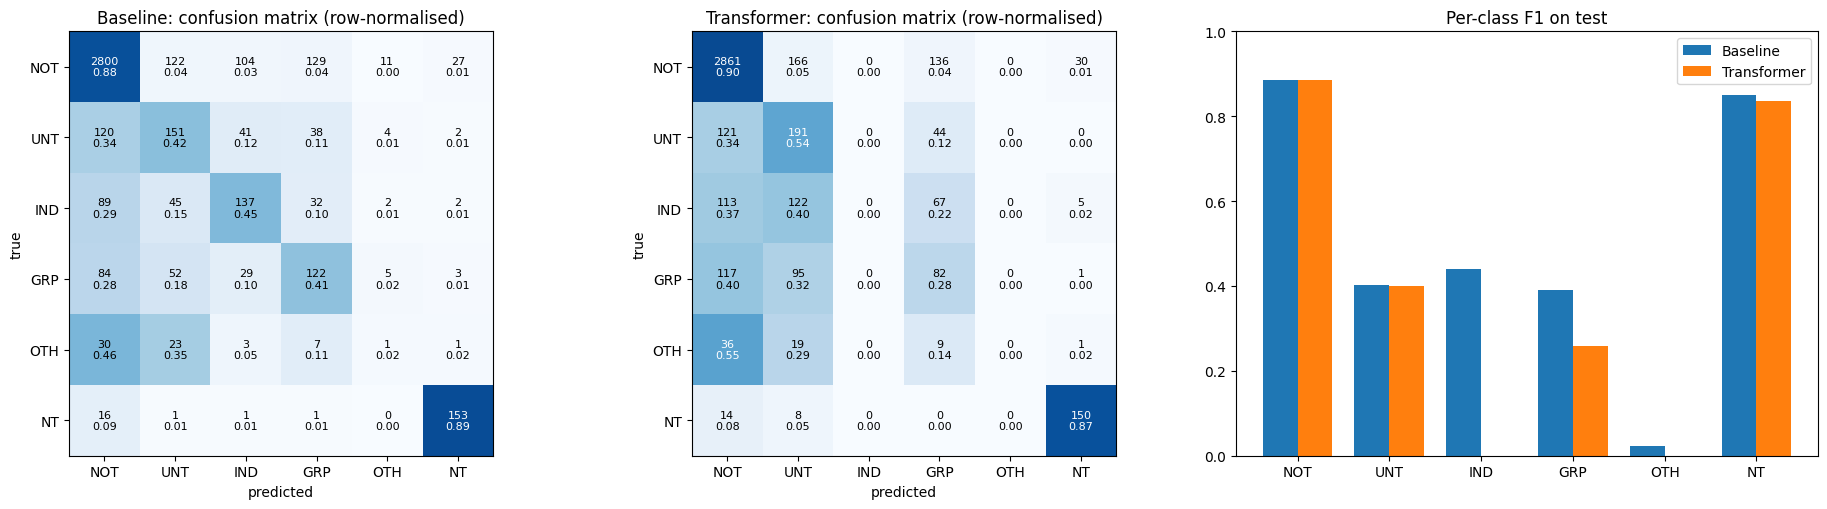

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, pred, title in [(axes[0], bl_pred_te, "Baseline"), (axes[1], tf_pred_te, "Transformer")]:
    cm = confusion_matrix(y_te, pred, labels=range(6))
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(6)); ax.set_xticklabels(SHORT); ax.set_yticks(range(6)); ax.set_yticklabels(SHORT)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{title}: confusion matrix (row-normalised)")
x = np.arange(6); w = 0.38
axes[2].bar(x - w / 2, per_class["baseline F1"], w, label="Baseline")
axes[2].bar(x + w / 2, per_class["transformer F1"], w, label="Transformer")
axes[2].set_xticks(x); axes[2].set_xticklabels(SHORT); axes[2].set_ylim(0, 1)
axes[2].set_title("Per-class F1 on test"); axes[2].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_and_f1.png", dpi=150); plt.show()

In [ ]:
# ---- McNemar's test: are the two systems' errors significantly different? ----
from scipy.stats import chi2 as chi2_dist
b = int(((bl_pred_te == y_te) & (tf_pred_te != y_te)).sum())   # baseline right, transformer wrong
c = int(((bl_pred_te != y_te) & (tf_pred_te == y_te)).sum())   # baseline wrong, transformer right
stat = (abs(b - c) - 1) ** 2 / max(b + c, 1)
p_value = float(1 - chi2_dist.cdf(stat, 1))
print(f"Baseline-only correct: {b} | Transformer-only correct: {c}")
print(f"McNemar chi2 (continuity-corrected) = {stat:.2f}, p = {p_value:.2e}")
RESULTS["mcnemar"] = {"baseline_only_correct": b, "transformer_only_correct": c, "chi2": stat, "p_value": p_value}

Baseline-only correct: 356 | Transformer-only correct: 276
McNemar chi2 (continuity-corrected) = 9.88, p = 1.68e-03


In [ ]:
# ---- Error analysis: failure cases of the transformer, grouped by error type ----
ea = test_df[["text", "label"]].copy()
ea["pred"], ea["conf"], ea["baseline_pred"] = tf_pred_te, tf_probs_te.max(1), bl_pred_te
ea["script"] = ea.text.map(lambda t: script_profile(t)["type"])
ea["n_words"] = ea.text.str.split().str.len()

def error_type(r):
    t, p = r.label, r.pred
    if t == p: return None
    if t == 5 or p == 5: return "Language-ID confusion (Not_Tamil)"
    if t == 0: return "False alarm (benign flagged as offensive)"
    if p == 0: return "Missed offence"
    return "Wrong offence type / target"

def likely_cause(r):
    c = []
    if r.n_words <= 3: c.append("very short, little context")
    if r.script in ("Tamil script", "mixed script"): c.append(f"{r.script} (minority in training data)")
    if r.error_type.startswith("Wrong offence"): c.append("target implicit (individual vs group vs other)")
    if r.error_type.startswith("Missed") and r.conf >= 0.8: c.append("confidently wrong: implicit/sarcastic offence or label noise")
    if r.error_type.startswith("False alarm") and r.conf >= 0.8: c.append("strong words used positively (fan slang) or label noise")
    if r.conf < 0.5: c.append("low confidence (would be flagged for human review)")
    if r.baseline_pred == r.label: c.append("baseline correct: lexical cue the transformer missed")
    return "; ".join(c) or "no surface cue - needs manual reading"

ea["error_type"] = ea.apply(error_type, axis=1)
wrong = ea[ea.error_type.notna()].copy()
wrong["likely_cause"] = wrong.apply(likely_cause, axis=1)

summary = wrong.error_type.value_counts().to_frame("count")
summary["% of errors"] = (100 * summary["count"] / len(wrong)).round(1)
display(Markdown(f"**{len(wrong)} errors out of {len(ea)} test comments ({len(wrong)/len(ea):.1%})**")); display(summary)
display(pd.crosstab(wrong.script, wrong.error_type))

# 2 most-confident + 2 least-confident failures per error type (≥ 10 cases)
cases = pd.concat([pd.concat([g.nlargest(2, "conf"), g.nsmallest(2, "conf")]).drop_duplicates()
                   for _, g in wrong.groupby("error_type")])
if len(cases) < 12:
    cases = pd.concat([cases, wrong.drop(cases.index).sample(12 - len(cases), random_state=SEED)])
show = cases.assign(true=cases.label.map(dict(enumerate(LABELS))), predicted=cases.pred.map(dict(enumerate(LABELS))),
                    baseline=cases.baseline_pred.map(dict(enumerate(SHORT))), text=cases.text.str.slice(0, 160))
with pd.option_context("display.max_colwidth", 160):
    display(show[["text", "true", "predicted", "conf", "baseline", "script", "error_type", "likely_cause"]]
            .reset_index(drop=True).round(3))
show.to_csv(f"{ART_DIR}/error_analysis_cases.csv", index=False)
wrong.to_csv(f"{ART_DIR}/all_test_errors.csv", index=False)
RESULTS["error_types"] = summary["count"].to_dict()

**1104 errors out of 4388 test comments (25.2%)**

,count,% of errors
error_type,,
Missed offence,387,35.1
Wrong offence type / target,356,32.2
False alarm (benign flagged as offensive),302,27.4
Language-ID confusion (Not_Tamil),59,5.3


error_type,False alarm (benign flagged as offensive),Language-ID confusion (Not_Tamil),Missed offence,Wrong offence type / target
script,,,,
Tamil script,65,1,53,33
mixed script,3,2,6,4
other script,0,2,0,0
romanized,234,54,328,319


,text,true,predicted,conf,baseline,script,error_type,likely_cause
0,En manasula irukara baarame koranjiruchu 🤣🤣🤣,Not_offensive,Offensive_Untargeted,0.275,IND,romanized,False alarm (benign flagged as offensive),low confidence (would be flagged for human review)
1,Idha veda kevalam edhum illada tamil ponungaluku,Not_offensive,Offensive_Untargeted,0.275,UNT,romanized,False alarm (benign flagged as offensive),low confidence (would be flagged for human review)
2,Viswasam reach aitunu petta kevalamaa pesathingu.....thala solrar pola,Not_offensive,Offensive_Untargeted,0.211,IND,romanized,False alarm (benign flagged as offensive),low confidence (would be flagged for human review)
3,Padam kand trailer kannaan vannnavar undoo,Not_offensive,Offensive_Untargeted,0.216,NT,romanized,False alarm (benign flagged as offensive),low confidence (would be flagged for human review)
4,Today trailer paaththu padam paakka wait panravangka like podungka.,Not_Tamil,Not_offensive,0.914,NOT,romanized,Language-ID confusion (Not_Tamil),no surface cue - needs manual reading
5,surya bhai iam big fan of surya,Not_Tamil,Not_offensive,0.909,NOT,romanized,Language-ID confusion (Not_Tamil),no surface cue - needs manual reading
6,Na oru malayali Jayam Ravi padam miss cheyilla,Not_Tamil,Offensive_Untargeted,0.231,NT,romanized,Language-ID confusion (Not_Tamil),low confidence (would be flagged for human review); baseline correct: lexical cue the transformer missed
7,Baboyii Enti edhii... Blok buster pakka,Not_Tamil,Offensive_Untargeted,0.253,NT,romanized,Language-ID confusion (Not_Tamil),low confidence (would be flagged for human review); baseline correct: lexical cue the transformer missed
8,Sema ragala. Waiting for tharamana sambavam,Offensive_Untargeted,Not_offensive,0.914,NOT,romanized,Missed offence,confidently wrong: implicit/sarcastic offence or label noise
9,Movie pathutu trailer paka vanthavanga like podunga,Offensive_Targeted_Other,Not_offensive,0.914,NOT,romanized,Missed offence,confidently wrong: implicit/sarcastic offence or label noise


### 6.3 Error analysis discussion
Read the table above together with the summary counts. In this dataset the failures usually fall into these patterns (confirm each one against your printed cases and quote examples in the report):

1. **Wrong target type.** Many errors stay *inside* the offensive classes (individual ↔ group ↔ other). The target is often implicit. For example, an insult to an actor can be read as against the individual or against his fan group. These errors are less harmful for moderation, because the comment is still flagged.
2. **Missed offence with high confidence.** Usually sarcasm, implicit insults without profanity, or offence that depends on context outside the comment (the video, the actor). Some cases are likely **annotation noise**; the cleaning step already found texts with conflicting labels.
3. **False alarms.** Strong words used *positively* in fan slang ("mass", "veri", "kolai mass") look offensive to a lexical model.
4. **Language-ID confusion.** Short romanized comments can be Tamil, Malayalam or Hindi. With only a few words, the `Not_Tamil` boundary is ambiguous.
5. **Tamil-script and very short comments** are rare in training. They have higher error rates relative to their frequency (see the script × error-type table).

**Implications / future work:** task-adaptive pre-training on unlabelled Tanglish comments (paper 3); label smoothing or relabelling of noisy examples; context features (video title); and merging the three targeted classes where the application does not need the target.

---
## §7 Edge Cases and Constraints *(Work Expected vii · CO5)*
We cover empty input, OOV and code-mixed text, input longer than the model window, class imbalance, unseen classes at inference, and latency and memory for one inference.

### 7.1 Confidence threshold τ (abstention for unseen classes)
A closed-set classifier always outputs one of its 6 labels, even for inputs that belong to *none* of them (spam, off-topic text, unseen languages). We therefore **abstain** when the top probability is below τ. We set τ on the **validation** set as the 5th percentile of confidence among correctly classified comments, so 95 % of correct predictions are kept.

Transformer tau = 0.269 | baseline tau = 0.248
At tau=0.269: coverage 87.8% | accuracy on accepted 0.814 | accuracy on abstained 0.280


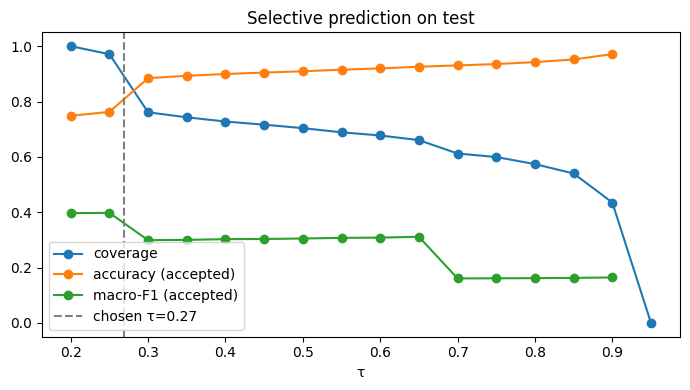

In [ ]:
def calibrate_tau(probs, y, q=0.05):
    correct = probs.argmax(1) == y
    return float(np.quantile(probs.max(1)[correct], q))

TAU = calibrate_tau(tf_probs_va, y_va)
BL_TAU = calibrate_tau(bl_probs_va, y_va)
print(f"Transformer tau = {TAU:.3f} | baseline tau = {BL_TAU:.3f}")

# Selective prediction on the TEST set: coverage vs quality as tau varies
conf_te = tf_probs_te.max(1)
rows = []
for t in np.round(np.linspace(0.2, 0.95, 16), 3):
    m = conf_te >= t
    rows.append(dict(tau=t, coverage=m.mean(),
                     accuracy=accuracy_score(y_te[m], tf_pred_te[m]) if m.any() else np.nan,
                     macro_f1=f1_score(y_te[m], tf_pred_te[m], average="macro") if m.any() else np.nan))
sel = pd.DataFrame(rows)
m = conf_te >= TAU
print(f"At tau={TAU:.3f}: coverage {m.mean():.1%} | accuracy on accepted {accuracy_score(y_te[m], tf_pred_te[m]):.3f} "
      f"| accuracy on abstained {accuracy_score(y_te[~m], tf_pred_te[~m]) if (~m).any() else float('nan'):.3f}")
plt.figure(figsize=(7, 4))
plt.plot(sel.tau, sel.coverage, "o-", label="coverage"); plt.plot(sel.tau, sel.accuracy, "o-", label="accuracy (accepted)")
plt.plot(sel.tau, sel.macro_f1, "o-", label="macro-F1 (accepted)"); plt.axvline(TAU, ls="--", c="gray", label=f"chosen τ={TAU:.2f}")
plt.xlabel("τ"); plt.title("Selective prediction on test"); plt.legend(); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/selective_prediction.png", dpi=150); plt.show()
RESULTS["abstention"] = {"tau": TAU, "baseline_tau": BL_TAU, "coverage_at_tau": float(m.mean()),
                         "acc_accepted": float(accuracy_score(y_te[m], tf_pred_te[m]))}

# Persist inference config and build the deployable predictors
save_config(ART_DIR, {"labels": LABELS, "max_len": MAX_LEN, "stride": CFG["stride"], "tau": TAU,
                      "baseline_tau": BL_TAU, "model_used": MODEL_USED, "baseline": BASELINE_NAME})
tf_predictor = TransformerPredictor(device=DEVICE, max_len=MAX_LEN, stride=CFG["stride"], tau=TAU,
                                    model=model, tokenizer=tok)
baseline.tau = BL_TAU

In [ ]:
# ---- 7.2 Edge-case suite (both systems) ----
filler_row = ea[(ea.label == 0) & (ea.pred == 0) & (ea.n_words >= 6)].nlargest(1, "conf").iloc[0]
LONG_BENIGN = " ".join([filler_row.text] * 60)
EDGE_CASES = [
    ("Empty string", ""),
    ("Whitespace only", "   \n\t  "),
    ("None / missing value", None),
    ("Non-string input (number)", 12345),
    ("Emoji only", "😂😂🔥🔥👏"),
    ("Punctuation only", "?!?!...."),
    ("OOV gibberish", "xqzvbn plrtk wwwqqq zzzkkk"),
    ("Elongated slang (OOV spellings)", "semmaaaaaa padammmm thalaivaaaaa"),
    ("Romanized Tamil, code-mixed", "Padam vera level, thalaivar mass entry 🔥 kandippa hit"),
    ("Tamil script", "இந்த படம் மிகவும் அருமையாக இருக்கிறது"),
    ("Mixed scripts in one sentence", "Trailer super ah iruku, இசை அருமை bro"),
    ("English only", "The background score is amazing, waiting for the release"),
    ("Unseen language: Hindi (Devanagari)", "यह फिल्म बहुत अच्छी है"),
    ("Unseen language: Malayalam script", "ഈ സിനിമ വളരെ നല്ലതാണ്"),
    ("Unseen language: romanized Hindi", "Yeh movie bahut acchi hai bhai"),
    ("Out-of-domain topic", "Please submit the lab record before Friday 5 pm"),
    ("Very long input (> model window)", LONG_BENIGN),
    ("Extremely long input (> MAX_CHARS)", "nalla padam " * 3000),
]
def run_suite(pred):
    out = []
    for name, text in EDGE_CASES:
        r = pred.predict(text)
        out.append({"case": name, "status": r["status"], "label": r["label"], "conf": r["confidence"],
                    "chunks": r["n_chunks"], "script": (r["script"] or {}).get("type"),
                    "tok/word": r["tokens_per_word"], "unk": r["unk_ratio"], "ms": r["latency_ms"],
                    "warnings": " | ".join(r["warnings"])[:140]})
    return pd.DataFrame(out)

edge_tf = run_suite(tf_predictor)
edge_bl = run_suite(baseline)
with pd.option_context("display.max_colwidth", 140):
    display(Markdown("**Transformer**")); display(edge_tf)
    display(Markdown("**Baseline**")); display(edge_bl[["case", "status", "label", "conf", "ms", "warnings"]])
edge_tf.to_csv(f"{ART_DIR}/edge_cases_transformer.csv", index=False)

**Transformer**

,case,status,label,conf,chunks,script,tok/word,unk,ms,warnings
0,Empty string,empty_input,None,NaN,0,None,NaN,NaN,0.03,Input is empty - nothing to classify.
1,Whitespace only,empty_input,None,NaN,0,None,NaN,NaN,0.01,Input is empty - nothing to classify.
2,None / missing value,empty_input,None,NaN,0,None,NaN,NaN,0.00,Input is empty - nothing to classify.
3,Non-string input (number),ok,Not_offensive,0.8854,1,no letters,2.00,0.000,179.60,
4,Emoji only,ok,Not_offensive,0.8040,1,no letters,1.00,1.000,11.78,No letters or digits (emoji/punctuation only) - low-evidence prediction. | 100% of tokens are unknown to the vocabulary.
5,Punctuation only,ok,Not_offensive,0.5638,1,no letters,6.00,0.000,16.63,No letters or digits (emoji/punctuation only) - low-evidence prediction.
6,OOV gibberish,ok,Not_Tamil,0.5755,1,romanized,3.75,0.000,28.33,
7,Elongated slang (OOV spellings),ok,Not_offensive,0.9134,1,romanized,2.67,0.000,15.93,
8,"Romanized Tamil, code-mixed",ok,Not_offensive,0.9143,1,romanized,1.67,0.067,13.91,
9,Tamil script,ok,Not_offensive,0.9142,1,Tamil script,1.20,0.000,11.15,


**Baseline**

,case,status,label,conf,ms,warnings
0,Empty string,empty_input,None,NaN,0.01,Input is empty - nothing to classify.
1,Whitespace only,empty_input,None,NaN,0.00,Input is empty - nothing to classify.
2,None / missing value,empty_input,None,NaN,0.00,Input is empty - nothing to classify.
3,Non-string input (number),ok,Not_offensive,0.3295,3.23,
4,Emoji only,ok,Not_offensive,0.3073,2.78,No letters or digits (emoji/punctuation only) - low-evidence prediction.
5,Punctuation only,ok,Not_offensive,0.2834,2.63,No letters or digits (emoji/punctuation only) - low-evidence prediction.
6,OOV gibberish,ok,Not_offensive,0.2853,2.76,
7,Elongated slang (OOV spellings),ok,Not_offensive,0.6125,2.72,
8,"Romanized Tamil, code-mixed",ok,Not_offensive,0.6811,3.01,
9,Tamil script,ok,Not_offensive,0.5082,3.08,


In [ ]:
# ---- 7.3 Long input: naive truncation vs sliding window ----
off_row = ea[(ea.label.isin(OFF_IDS)) & (ea.pred == ea.label) & (ea.n_words <= 25)].nlargest(1, "conf").iloc[0]
long_text = LONG_BENIGN + " " + off_row.text        # offensive sentence hidden at the very END
n_tok = len(tok(clean_text(long_text))["input_ids"])
trunc = predict_probs(model, [clean_text(long_text)])[0]
slide = tf_predictor.predict(long_text)
display(pd.DataFrame([
    {"strategy": f"Naive truncation to {MAX_LEN} tokens", "prediction": LABELS[int(trunc.argmax())],
     "P(offensive)": float(trunc[OFF_IDS].sum())},
    {"strategy": f"Sliding window ({slide['n_chunks']} chunks, {slide['aggregation']})", "prediction": slide["label"],
     "P(offensive)": sum(slide["probs"][LABELS[i]] for i in OFF_IDS)},
]).round(3))
print(f"Input length: {n_tok} tokens. Hidden offensive sentence (gold = {LABELS[off_row.label]}): {off_row.text[:120]}")
RESULTS["long_input_demo"] = {"tokens": n_tok, "truncation_pred": LABELS[int(trunc.argmax())], "sliding_pred": slide["label"]}

,strategy,prediction,P(offensive)
0,Naive truncation to 96 tokens,Not_offensive,0.080
1,"Sliding window (2 chunks, mean over chunks)",Not_offensive,0.079


Input length: 791 tokens. Hidden offensive sentence (gold = Offensive_Untargeted): Enna da over buildup ah iruku


### 7.4 Class imbalance
`Not_offensive` makes up roughly 70 % of the data, while `Offensive_Targeted_Other` is about 1 %. We counter this in three ways:
* **Training:** class-balanced weights in both models (sqrt-dampened for the transformer).
* **Model selection:** by **macro-F1**, which weights every class equally.
* **Reporting:** per-class P/R/F1 and confusion matrices, so rare-class failures are visible.

The next cell compares the true and predicted class distributions, and recall on rare classes.

In [ ]:
imb = pd.DataFrame({
    "train share %": 100 * np.bincount(y_tr, minlength=6) / len(y_tr),
    "test true %": 100 * np.bincount(y_te, minlength=6) / len(y_te),
    "baseline predicted %": 100 * np.bincount(bl_pred_te, minlength=6) / len(y_te),
    "transformer predicted %": 100 * np.bincount(tf_pred_te, minlength=6) / len(y_te),
    "baseline recall": per_class["baseline R"].values,
    "transformer recall": per_class["transformer R"].values,
    "loss weight": cw,
}, index=LABELS).round(3)
display(imb)
maj_only = f1_score(y_te, np.zeros_like(y_te), average="macro")
print(f"Reference: always predicting 'Not_offensive' gives accuracy {np.mean(y_te == 0):.3f} but macro-F1 only {maj_only:.3f}"
      " - this is why accuracy alone is misleading here.")

,train share %,test true %,baseline predicted %,transformer predicted %,baseline recall,transformer recall,loss weight
Not_offensive,72.267,72.767,71.536,74.339,0.877,0.896,0.273
Offensive_Untargeted,8.285,8.113,8.979,13.696,0.424,0.537,0.805
Offensive_Targeted_Individual,6.702,6.996,7.179,0.000,0.446,0.000,0.895
Offensive_Targeted_Group,7.302,6.723,7.498,7.703,0.414,0.278,0.857
Offensive_Targeted_Other,1.299,1.481,0.524,0.000,0.015,0.000,2.033
Not_Tamil,4.146,3.920,4.284,4.262,0.890,0.872,1.138


Reference: always predicting 'Not_offensive' gives accuracy 0.728 but macro-F1 only 0.140 - this is why accuracy alone is misleading here.


### 7.5 Unseen classes at inference
* **Unseen languages** (Hindi, Malayalam script, …): the model has a `Not_Tamil` class, and a **script guard** marks any input that is mostly non-Tamil, non-Latin script as `out_of_scope_language` (see §7.2).
* **Unseen categories** (spam, off-topic text, new kinds of abuse): the closed-set softmax cannot output a new label, so the **τ-abstention** returns `uncertain` and routes the comment to a human (see §7.1).
* **Honest limitation:** softmax confidence is often *over*confident on fluent out-of-domain text, such as the "lab record" sentence above. Abstention reduces this risk but does not remove it. Proper fixes are energy-based OOD scores or training with an explicit "other" class.

### 7.6 Latency and memory for one inference

In [ ]:
import psutil
def bench(pred, text, n=30):
    for _ in range(3):
        pred.predict(text)
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); pred.predict(text)
        if DEVICE == "cuda": torch.cuda.synchronize()
        ts.append((time.perf_counter() - t0) * 1000)
    return float(np.percentile(ts, 50)), float(np.percentile(ts, 95))

typical = test_df.text.iloc[int(np.argsort(ea.n_words.values)[len(ea) // 2])]   # median-length comment
lat = []
p50, p95 = bench(baseline, typical); lat.append(("Baseline", "CPU", "typical comment", p50, p95))
if DEVICE == "cuda":
    for label_, txt in [("typical comment", typical), ("long input (sliding window)", LONG_BENIGN)]:
        p50, p95 = bench(tf_predictor, txt); lat.append(("Transformer", "GPU " + gpu_name, label_, p50, p95))
    torch.cuda.reset_peak_memory_stats(); before = torch.cuda.memory_allocated()
    tf_predictor.predict(typical)
    gpu_act_mb = (torch.cuda.max_memory_allocated() - before) / 1e6
    gpu_weights_mb = before / 1e6
else:
    gpu_act_mb = gpu_weights_mb = float("nan")

rss0 = psutil.Process().memory_info().rss
cpu_predictor = TransformerPredictor(TF_DIR, device="cpu", max_len=MAX_LEN, stride=CFG["stride"], tau=TAU)
cpu_rss_mb = (psutil.Process().memory_info().rss - rss0) / 1e6
p50, p95 = bench(cpu_predictor, typical, n=15)
lat.append(("Transformer", f"CPU ({torch.get_num_threads()} threads)", "typical comment", p50, p95))
del cpu_predictor; gc.collect()

lat_df = pd.DataFrame(lat, columns=["system", "hardware", "input", "p50 ms", "p95 ms"]).round(1)
display(lat_df)

n_params = sum(p.numel() for p in model.parameters())
dir_mb = sum(os.path.getsize(os.path.join(TF_DIR, f)) for f in os.listdir(TF_DIR)) / 1e6
mem_df = pd.DataFrame([
    ("Transformer parameters", f"{n_params/1e6:.1f} M"),
    ("Transformer weights on disk", f"{dir_mb:.0f} MB"),
    ("GPU memory: weights resident", f"{gpu_weights_mb:.0f} MB"),
    ("GPU memory: extra peak for one inference", f"{gpu_act_mb:.1f} MB"),
    ("CPU RAM added by loading the model", f"{cpu_rss_mb:.0f} MB"),
    ("Baseline model file", f"{os.path.getsize(f'{ART_DIR}/baseline.joblib')/1e6:.1f} MB"),
], columns=["quantity", "value"])
display(mem_df)
RESULTS["latency_ms"] = lat_df.to_dict(orient="records")
RESULTS["memory"] = dict(mem_df.values)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,system,hardware,input,p50 ms,p95 ms
0,Baseline,CPU,typical comment,3.3,3.8
1,Transformer,GPU Tesla T4,typical comment,8.8,14.2
2,Transformer,GPU Tesla T4,long input (sliding window),19.1,19.8
3,Transformer,CPU (1 threads),typical comment,119.8,125.9


,quantity,value
0,Transformer parameters,237.6 M
1,Transformer weights on disk,957 MB
2,GPU memory: weights resident,2880 MB
3,GPU memory: extra peak for one inference,0.5 MB
4,CPU RAM added by loading the model,78 MB
5,Baseline model file,13.7 MB


---
## §8 Testing *(Rubric: test cases and validation of outputs against expected results)*
There are three layers of tests:
1. **Unit tests** for preprocessing, the input guard, chunking and output contracts, each with an expected result.
2. **Golden-set tests**: stratified test comments with gold labels, as expected-vs-actual output validation.
3. **Behavioural invariance tests** (CheckList, Ribeiro et al., ACL 2020): label-preserving perturbations should not flip the prediction.

In [ ]:
TESTS = []
def check(group, name, expected, actual, passed):
    TESTS.append({"group": group, "test": name, "expected": str(expected)[:60], "actual": str(actual)[:60],
                  "result": "PASS" if passed else "FAIL"})

# --- preprocessing ---
check("preprocess", "URL normalised", "contains 'URL'", clean_text("see https://t.co/x now"), "URL" in clean_text("see https://t.co/x now"))
check("preprocess", "mention normalised", "@USER", clean_text("@rahul_99 hi"), clean_text("@rahul_99 hi").startswith("@USER"))
check("preprocess", "hashtag split", "Thalaivar", clean_text("#Thalaivar"), clean_text("#Thalaivar") == "Thalaivar")
check("preprocess", "elongation squashed", "semmaa", clean_text("semmaaaaaa"), clean_text("semmaaaaaa") == "semmaa")
check("preprocess", "whitespace collapsed", "a b", clean_text("  a \n\t b "), clean_text("  a \n\t b ") == "a b")
check("preprocess", "None safe", "''", clean_text(None), clean_text(None) == "")
check("script", "Tamil script detected", "Tamil script", script_profile("வணக்கம் நண்பா")["type"], script_profile("வணக்கம் நண்பா")["type"] == "Tamil script")
check("script", "romanized detected", "romanized", script_profile("vanakkam nanba")["type"], script_profile("vanakkam nanba")["type"] == "romanized")
check("script", "other script detected", "other script", script_profile("यह फिल्म")["type"], script_profile("यह फिल्म")["type"] == "other script")

# --- input guard & output contract (both predictors) ---
for pred in (tf_predictor, baseline):
    g = pred.name
    for nm, txt in [("empty", ""), ("whitespace", "  \n "), ("None", None)]:
        r = pred.predict(txt); check(g, f"{nm} -> empty_input", "empty_input", r["status"], r["status"] == "empty_input")
    r = pred.predict("padam semma mass")
    check(g, "probabilities sum to 1", 1.0, round(sum(r["probs"].values()), 4), abs(sum(r["probs"].values()) - 1) < 1e-3)
    check(g, "label is one of 6 classes", "in LABELS", r["label"], r["label"] in LABELS)
    check(g, "status valid", "ok/uncertain", r["status"], r["status"] in ("ok", "uncertain"))
    r2 = pred.predict("padam semma mass")
    check(g, "deterministic", "same probs", "", np.allclose(list(r["probs"].values()), list(r2["probs"].values()), atol=1e-5))
    r = pred.predict(12345); check(g, "non-string input handled", "ok/uncertain", r["status"], r["status"] in ("ok", "uncertain"))
    r = pred.predict("x" * (MAX_CHARS + 500)); check(g, "over-length input truncated", "warning", r["warnings"][:1], any("truncated" in w for w in r["warnings"]))
    r = pred.predict("यह फिल्म बहुत अच्छी है"); check(g, "other script -> out_of_scope", "out_of_scope_language", r["status"], r["status"] == "out_of_scope_language")

r = tf_predictor.predict(LONG_BENIGN)
check("transformer", "long input -> multiple chunks", ">1", r["n_chunks"], r["n_chunks"] > 1)
r = tf_predictor.predict(long_text)
check("transformer", "offence hidden at end of long text detected", "offensive", r["label"], r["label"] in [LABELS[i] for i in OFF_IDS])
short_idx = [i for i, t in enumerate(te_clean) if len(tok(t)["input_ids"]) <= MAX_LEN][:5]
batch_p = predict_probs(model, [te_clean[i] for i in short_idx]).argmax(1)
single_p = [LABELS.index(tf_predictor.predict(test_df.text[i])["label"]) for i in short_idx]
check("transformer", "batch vs single-item consistency", list(batch_p), single_p, list(batch_p) == single_p)

unit = pd.DataFrame(TESTS)
print(f"Unit tests: {(unit.result == 'PASS').sum()}/{len(unit)} passed")
with pd.option_context("display.max_rows", 100):
    display(unit)

Unit tests: 31/32 passed


,group,test,expected,actual,result
0,preprocess,URL normalised,contains 'URL',see URL now,PASS
1,preprocess,mention normalised,@USER,@USER hi,PASS
2,preprocess,hashtag split,Thalaivar,Thalaivar,PASS
3,preprocess,elongation squashed,semmaa,semmaa,PASS
4,preprocess,whitespace collapsed,a b,a b,PASS
5,preprocess,None safe,'',,PASS
6,script,Tamil script detected,Tamil script,Tamil script,PASS
7,script,romanized detected,romanized,romanized,PASS
8,script,other script detected,other script,other script,PASS
9,MuRIL transformer,empty -> empty_input,empty_input,empty_input,PASS


In [ ]:
# --- Golden set: 5 stratified examples per class, expected = gold label ---
gold = pd.concat([g.sample(min(5, len(g)), random_state=SEED) for _, g in test_df.groupby("label")])
gold_rows = []
for t, y in zip(gold.text, gold.label):
    r = tf_predictor.predict(t)
    gold_rows.append({"text": t[:90], "expected": LABELS[y], "predicted": r["label"], "conf": r["confidence"],
                      "status": r["status"], "result": "PASS" if r["label"] == LABELS[y] else "FAIL"})
gold_df = pd.DataFrame(gold_rows)
print(f"Golden set: {(gold_df.result == 'PASS').sum()}/{len(gold_df)} match the gold label")
with pd.option_context("display.max_colwidth", 90):
    display(gold_df)

# --- Behavioural invariance tests on 200 random test comments ---
rng_sample = test_df.sample(200, random_state=SEED).text.tolist()
base_labels = [tf_predictor.predict(t)["label"] for t in rng_sample]
perturb = {
    "append URL": lambda t: t + " https://youtu.be/abc123",
    "prepend @mention": lambda t: "@someone " + t,
    "extra whitespace": lambda t: "  " + t.replace(" ", "   ") + " \n",
    "character elongation": lambda t: re.sub(r"([aeiou])", r"\1\1\1\1", t, count=2),
    "trailing punctuation": lambda t: t + " !!!",
}
inv_rows = []
for name, f in perturb.items():
    same = np.mean([tf_predictor.predict(f(t))["label"] == b for t, b in zip(rng_sample, base_labels)])
    inv_rows.append({"perturbation": name, "prediction unchanged": round(float(same), 3),
                     "result": "PASS" if same >= 0.90 else "FAIL (≥0.90 expected)"})
inv_df = pd.DataFrame(inv_rows); display(inv_df)

pd.concat([unit.assign(kind="unit"), gold_df.assign(kind="golden"), inv_df.assign(kind="invariance")]) \
  .to_csv(f"{ART_DIR}/test_report.csv", index=False)
RESULTS["tests"] = {"unit_passed": int((unit.result == "PASS").sum()), "unit_total": len(unit),
                    "golden_passed": int((gold_df.result == "PASS").sum()), "golden_total": len(gold_df),
                    "invariance": inv_df.set_index("perturbation")["prediction unchanged"].to_dict()}

Golden set: 12/30 match the gold label


,text,expected,predicted,conf,status,result
0,Verithanam naa epdii erukanum nu ninikarevangaa mattum hit likee,Not_offensive,Not_offensive,0.9083,ok,PASS
1,Mediava ipathan sariya use pana kathukitanga,Not_offensive,Offensive_Untargeted,0.2679,uncertain,FAIL
2,You see view 102k but Likes 150k,Not_offensive,Offensive_Untargeted,0.2531,uncertain,FAIL
3,Petta pongalo pongal coming to gift rajini sri gift for fens,Not_offensive,Not_offensive,0.9107,ok,PASS
4,"Super star fans kelam nalla theeni potrukarr karthik subaraj, thalaivar charisma vera ...",Not_offensive,Not_offensive,0.8667,ok,PASS
5,ivanuku nadikave varathu...intha padam oduna mathiri than...en da comedy pandringa...b...,Offensive_Untargeted,Offensive_Untargeted,0.2685,uncertain,PASS
6,Anyone after Kaappaan Teaser ?,Offensive_Untargeted,Not_offensive,0.8899,ok,FAIL
7,teaser nalla thaan da irukku..loosu pasangala...,Offensive_Untargeted,Offensive_Untargeted,0.2719,ok,PASS
8,Apdiye poiru kola kandula irukan mass thalaivasweet sapda poro,Offensive_Untargeted,Offensive_Targeted_Group,0.2666,uncertain,FAIL
9,Haiyooo.. hero roll ku indhe munji sariye waradhu.,Offensive_Untargeted,Offensive_Untargeted,0.2085,uncertain,PASS


,perturbation,prediction unchanged,result
0,append URL,0.940,PASS
1,prepend @mention,0.940,PASS
2,extra whitespace,1.000,PASS
3,character elongation,0.975,PASS
4,trailing punctuation,0.950,PASS


---
## §9 Live Demo *(Work Expected viii · CO5)*
A Gradio app with **single-comment** and **batch** modes, a model switch (transformer vs baseline), class probabilities, and the edge-case flags. Gradio also exposes a **REST API** automatically (`/classify`, `/classify_batch`). The same `app.py` runs outside Colab with `python app.py`.

In [ ]:
%%writefile app.py
"""Gradio demo + REST API for the Tamil-English offensive language detector.

Standalone:  python app.py [--share]      (expects ./artifacts produced by the notebook)
API usage:   from gradio_client import Client
             Client("<url>").predict("comment text", "MuRIL transformer (fine-tuned)", api_name="/classify")
"""
import json
import os
import sys

import gradio as gr
import pandas as pd

from nlp_core import PRETTY, BaselinePredictor, TransformerPredictor

ENGINES = ["MuRIL transformer (fine-tuned)", "TF-IDF + linear baseline"]


def verdict_markdown(r):
    if r["status"] == "empty_input":
        return "### ✋ Nothing to classify\nType or paste a comment first."
    lab, conf = r["label"], r["confidence"]
    icon = "✅" if lab == "Not_offensive" else ("🌐" if lab == "Not_Tamil" else "⚠️")
    head = f"## {icon} {PRETTY[lab]}"
    if r["status"] == "uncertain":
        head = f"## ❓ Uncertain - needs human review\nBest guess: **{PRETTY[lab]}**"
    elif r["status"] == "out_of_scope_language":
        head = f"## 🌐 Out-of-scope language\nModel's guess: **{PRETTY[lab]}**"
    script = (r.get("script") or {}).get("type", "-")
    sub = f"Confidence **{conf:.0%}** · {r['latency_ms']:.0f} ms · script: *{script}* · window chunks: {r['n_chunks']}"
    notes = "\n".join(f"- {w}" for w in r["warnings"])
    return head + "\n\n" + sub + (f"\n\n**Notes**\n{notes}" if notes else "")


def build_demo(tf_pred, base_pred=None, examples=None):
    engines = {ENGINES[0]: tf_pred}
    if base_pred is not None:
        engines[ENGINES[1]] = base_pred

    def classify(text, engine):
        r = engines[engine].predict(text)
        probs = {PRETTY[k]: v for k, v in r["probs"].items()} if r["probs"] else None
        keys = ["status", "label", "confidence", "latency_ms", "n_chunks", "aggregation", "script",
                "n_tokens", "unk_ratio", "tokens_per_word", "cleaned", "warnings"]
        return verdict_markdown(r), probs, {k: r.get(k) for k in keys}

    def classify_batch(block, engine):
        rows = []
        for line in [l for l in (block or "").splitlines() if l.strip()][:200]:
            r = engines[engine].predict(line)
            rows.append({"comment": line[:120], "verdict": PRETTY.get(r["label"], "-"),
                         "confidence": r["confidence"], "status": r["status"]})
        return pd.DataFrame(rows, columns=["comment", "verdict", "confidence", "status"])

    with gr.Blocks(title="Tamil-English Offensive Comment Detector") as demo:
        gr.Markdown("# 🛡️ Tamil–English Offensive Comment Detector\n"
                    "Detects offensive language in **code-mixed Tamil–English** comments (Tanglish, Tamil script "
                    "or mixed) and identifies the **target** of the offence. It abstains when unsure and flags "
                    "out-of-scope languages.")
        with gr.Tab("Single comment"):
            with gr.Row():
                with gr.Column(scale=3):
                    inp = gr.Textbox(label="Comment", lines=4,
                                     placeholder="e.g. Padam vera level, thalaivar mass entry 🔥")
                    engine = gr.Radio(list(engines), value=ENGINES[0], label="Model")
                    with gr.Row():
                        btn = gr.Button("Classify", variant="primary")
                        clr = gr.Button("Clear")
                with gr.Column(scale=2):
                    verdict = gr.Markdown()
                    probs = gr.Label(label="Class probabilities", num_top_classes=6)
            details = gr.JSON(label="Details: preprocessing, edge-case flags, latency")
            if examples:
                gr.Examples(examples=[[e] for e in examples], inputs=[inp],
                            label="Examples (held-out test comments + edge cases)")
            btn.click(classify, [inp, engine], [verdict, probs, details], api_name="classify")
            inp.submit(classify, [inp, engine], [verdict, probs, details])
            clr.click(lambda: ("", "", None, None), None, [inp, verdict, probs, details])
        with gr.Tab("Batch"):
            binp = gr.Textbox(label="One comment per line (max 200)", lines=10)
            bengine = gr.Radio(list(engines), value=ENGINES[0], label="Model")
            bbtn = gr.Button("Classify all", variant="primary")
            bout = gr.Dataframe(label="Results")
            bbtn.click(classify_batch, [binp, bengine], bout, api_name="classify_batch")
        with gr.Tab("About"):
            gr.Markdown(
                "**Model:** MuRIL fine-tuned on Offenseval Dravidian (Tamil), CC BY 4.0.  \n"
                "**Pipeline:** input guard → normalisation → WordPiece + sliding window → MuRIL → "
                "max-offensive-chunk aggregation → confidence threshold τ → script guard.  \n"
                "**Statuses:** `ok`, `uncertain` (confidence < τ, send to human), "
                "`out_of_scope_language`, `empty_input`.  \n"
                "**Intended use:** assist human moderators; not for fully automatic removal.")
    return demo


if __name__ == "__main__":
    art = os.environ.get("ARTIFACT_DIR", "artifacts")
    tf = TransformerPredictor.from_artifacts(art)
    bl = BaselinePredictor.from_artifacts(art)
    ex_path = os.path.join(art, "demo_examples.json")
    ex = json.load(open(ex_path)) if os.path.exists(ex_path) else None
    build_demo(tf, bl, ex).launch(share="--share" in sys.argv)

Writing app.py


In [ ]:
import app
importlib.reload(app)

# Demo examples: one confidently-correct, short test comment per class + edge cases
examples = []
for c in range(6):
    cand = ea[(ea.label == c) & (ea.pred == c) & (ea.n_words.between(4, 30))]
    if len(cand):
        examples.append(cand.nlargest(1, "conf").text.iloc[0])
examples += ["இந்த படம் மிகவும் அருமையாக இருக்கிறது",
             "Trailer super ah iruku, இசை அருமை bro",
             "😂😂🔥🔥👏",
             "यह फिल्म बहुत अच्छी है",
             long_text]
with open(f"{ART_DIR}/demo_examples.json", "w") as f:
    json.dump(examples, f, ensure_ascii=False, indent=1)

demo = app.build_demo(tf_predictor, baseline, examples)
demo.launch(share=True, debug=False)   # public *.gradio.live link printed below; the inline app works too

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ce2899b0e2d73b4a3b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip -q install gradio
import os, sys, joblib
os.chdir("/content/nlp_project"); sys.path.insert(0, "/content/nlp_project")

from nlp_core import TransformerPredictor, BaselinePredictor, load_config
import app

ART = "artifacts"
cfg = load_config(ART)
device = "cuda" if __import__("torch").cuda.is_available() else "cpu"

tf_pred = TransformerPredictor(f"{ART}/transformer", device=device,
                               max_len=cfg["max_len"], stride=cfg["stride"], tau=cfg["tau"])
bl_pred = BaselinePredictor(joblib.load(f"{ART}/baseline.joblib"))
bl_pred.tau = cfg["baseline_tau"]

demo = app.build_demo(tf_pred, bl_pred)   # add an examples list if you want clickable examples
demo.launch(share=True)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d2b9ee271ffa3a65c2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
## §10 Deliverables and Success-Criteria Scorecard
Writes `README.md`, `requirements.txt`, `run.sh` and `results.json`, and packages the repository (without the large model weights) as a zip.

In [ ]:
lat_lookup = {(r["system"], r["hardware"].split()[0], r["input"]): r for r in RESULTS["latency_ms"]}
gpu_p95 = next((r["p95 ms"] for k, r in lat_lookup.items() if k[0] == "Transformer" and k[1] == "GPU" and k[2] == "typical comment"), float("nan"))
cpu_p95 = next((r["p95 ms"] for k, r in lat_lookup.items() if k[0] == "Transformer" and k[1] == "CPU"), float("nan"))
tf_row, bl_row = comp.iloc[1], comp.iloc[0]
edge_ok = edge_tf.status.isin(["ok", "uncertain", "out_of_scope_language", "empty_input"]).all()
score = pd.DataFrame([
    ("S1", "Transformer weighted-F1 ≥ 0.74", round(tf_row["Weighted-F1"], 4), tf_row["Weighted-F1"] >= 0.74),
    ("S2", "Macro-F1 gain over baseline ≥ 0.03", round(tf_row["Macro-F1"] - bl_row["Macro-F1"], 4), tf_row["Macro-F1"] - bl_row["Macro-F1"] >= 0.03),
    ("S3", "McNemar p < 0.05", f"{p_value:.1e}", p_value < 0.05),
    ("S4", "GPU p95 latency ≤ 50 ms", gpu_p95, gpu_p95 <= 50),
    ("S5", "CPU p95 latency ≤ 500 ms", cpu_p95, cpu_p95 <= 500),
    ("S6", "All edge cases return an explicit status", f"{len(edge_tf)} cases", bool(edge_ok)),
], columns=["id", "criterion", "measured", "met"])
display(score)
RESULTS["success_criteria"] = score.astype(str).to_dict(orient="records")

In [ ]:
import sklearn, gradio as _gr, datasets as _ds
with open("requirements.txt", "w") as f:
    f.write(f"""torch=={torch.__version__.split('+')[0]}
transformers=={_tf.__version__}
datasets=={_ds.__version__}
scikit-learn=={sklearn.__version__}
gradio=={_gr.__version__}
pandas=={pd.__version__}
numpy=={np.__version__}
matplotlib
scipy
psutil
joblib
tqdm
""")

with open("run.sh", "w") as f:
    f.write("""#!/usr/bin/env bash
# Reproducible end-to-end run (fixed seed = 42 in the notebook config).
set -e
pip install -r requirements.txt
pip install jupyter nbconvert
jupyter nbconvert --to notebook --execute NLP_MicroProject_Offensive_Tamil.ipynb \\
        --output executed.ipynb --ExecutePreprocessor.timeout=-1
python app.py --share        # launches the demo from ./artifacts
""")
os.chmod("run.sh", 0o755)

RESULTS["config"] = {**CFG, "max_len": MAX_LEN, "model_used": MODEL_USED, "baseline": BASELINE_NAME}
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=str)

try:
    res_md = comp.round(4).to_markdown()
except ImportError:   # 'tabulate' not installed
    res_md = "```\n" + comp.round(4).to_string() + "\n```"
readme = f"""# Offensive Language Detection in Tamil–English Code-Mixed Text
UCS3564 NLP Micro Project — SSN College of Engineering (R2024, Sem V, 2026–27)

An end-to-end NLP system that takes a raw social-media comment (romanized Tamil, Tamil script or mixed) and returns
one of 6 labels (not offensive / offensive untargeted / targeted at individual / group / other / not Tamil), with
probabilities, abstention when unsure, and edge-case flags. Transformer component: **{MODEL_USED}** fine-tuned.

![architecture](figures/architecture.png)

## Results (held-out test set, {len(test_df):,} comments)
{res_md}

McNemar test transformer vs baseline: p = {p_value:.1e}. More detail in `results.json` and `artifacts/`.

## Dataset
Offenseval Dravidian (Tamil), Chakravarthi et al., DravidianLangTech @ EACL 2021; Hugging Face
`community-datasets/offenseval_dravidian`. **Licence: CC BY 4.0.** The fixed split is stored in `data/`.

## How to run
* **Colab (recommended):** open `NLP_MicroProject_Offensive_Tamil.ipynb`, select a T4 GPU, Run all.
* **Local:** `bash run.sh` (executes the notebook with seed 42, then launches the demo).
* **Demo only (after training):** `python app.py --share`.
* **REST API:** `from gradio_client import Client; Client(URL).predict("text", "MuRIL transformer (fine-tuned)", api_name="/classify")`

## Repository structure
```
NLP_MicroProject_Offensive_Tamil.ipynb   full pipeline (problem → data → baseline → transformer → evaluation → edge cases → tests → demo)
nlp_core.py        preprocessing, script ID, input guard, predictors (sliding window + abstention)
app.py             Gradio UI + REST API
data/              fixed train / val / test split (CSV)
artifacts/         baseline.joblib, transformer/ (weights, not in git), inference_config.json, MODEL_CARD.md,
                   error_analysis_cases.csv, edge_cases_transformer.csv, test_report.csv
figures/           architecture, data overview, training curves, confusion matrices, selective prediction
results.json       all metrics, latency, memory, tests, success criteria
requirements.txt   pinned versions   ·   run.sh   reproducible run script
```

## Declaration of AI-assistant use (required by the course)
Parts of the code and notebook text were generated with the help of an AI assistant (Anthropic Claude) and
then run, checked and edited by the team. Every team member has reviewed the whole pipeline and can explain it.

## Team and contributions
| Member | Register no. | Contribution |
|---|---|---|
| Arjun Balaji | 3122245001022 | |
| | | |
| | | |

## References
1. Chakravarthi et al. Findings of the Shared Task on Offensive Language Identification in Tamil, Malayalam, and Kannada. DravidianLangTech @ EACL 2021.
2. Chakravarthi et al. DravidianCodeMix: sentiment analysis and offensive language identification dataset for Dravidian languages in code-mixed text. Language Resources and Evaluation, 2022.
3. Jayanthi & Gupta. SJ_AJ@DravidianLangTech-EACL2021: Task-Adaptive Pre-Training of Multilingual BERT Models for Offensive Language Identification. 2021.
4. Hande et al. Offensive Language Identification in Low-resourced Code-mixed Dravidian Languages using Pseudo-labeling. arXiv, 2021.
5. Khanuja et al. MuRIL: Multilingual Representations for Indian Languages. arXiv, 2021.
6. Kakwani et al. IndicNLPSuite: Monolingual Corpora, Evaluation Benchmarks and Pre-trained Multilingual Language Models for Indian Languages. Findings of EMNLP 2020.
7. Conneau et al. Unsupervised Cross-lingual Representation Learning at Scale. ACL 2020.
8. Ribeiro et al. Beyond Accuracy: Behavioral Testing of NLP Models with CheckList. ACL 2020.
"""
with open("README.md", "w") as f:
    f.write(readme)
with open(".gitignore", "w") as f:
    f.write("artifacts/transformer/\n__pycache__/\n*.zip\n")

# Package everything except the ~1 GB transformer weights
stage = "/tmp/nlp_repo"
shutil.rmtree(stage, ignore_errors=True)
shutil.copytree(PROJECT_DIR, stage, ignore=shutil.ignore_patterns("transformer", "__pycache__", "*.zip"))
zip_path = shutil.make_archive(os.path.join(PROJECT_DIR, "nlp_microproject_repo"), "zip", stage)
print("Repository package:", zip_path, f"({os.path.getsize(zip_path)/1e6:.1f} MB)")
print("Files:", sorted(os.listdir(PROJECT_DIR)))

Repository package: /content/nlp_project/nlp_microproject_repo.zip (9.5 MB)
Files: ['.gitignore', '.gradio', 'README.md', '__pycache__', 'app.py', 'artifacts', 'data', 'figures', 'nlp_core.py', 'nlp_microproject_repo.zip', 'requirements.txt', 'results.json', 'run.sh']


In [ ]:
# Optional: download the repo zip, and back up the trained transformer to Google Drive
SAVE_TO_DRIVE = False
try:
    from google.colab import files
    files.download(zip_path)
    if SAVE_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        shutil.copytree(ART_DIR, "/content/drive/MyDrive/nlp_microproject_artifacts", dirs_exist_ok=True)
        print("Artifacts (including model weights) copied to Drive.")
except ImportError:
    print("Not running on Colab - files are in", PROJECT_DIR)

### Final checklist
| Requirement | Where |
|---|---|
| (i) Application, I/O, users, need, measurable criteria, ≥ 5 papers, gap | §1 |
| (ii) Corpus, licence, size, annotation scheme, fixed split | §2, `data/` |
| (iii) Architecture diagram, modules, justified choices | §3, `figures/architecture.png`, `nlp_core.py` |
| (iv) TF-IDF + traditional classifier baseline | §4 |
| (v) Fine-tuned transformer, model card, hyper-parameters, compute | §5, `artifacts/MODEL_CARD.md` |
| (vi) Accuracy / P / R / F1, baseline vs transformer, ≥ 10 failure cases | §6 |
| (vii) Empty input, OOV and code-mixed text, long input, imbalance, unseen classes, latency and memory | §7 |
| Testing: test cases vs expected results | §8, `artifacts/test_report.csv` |
| (viii) Gradio app + REST API, live demo | §9, `app.py` |
| Deliverables: README (with AI-use declaration), requirements.txt, run script, fixed seed | §10 |